# ICT 5143 · Problem 9 — Fairness Preservation under Computational Budgets in Probabilistic Decision Systems
**Author:** Shreeya Kamath

**Project notebook — runs on the REAL UCI Bank Marketing data (`bank-additional-full.csv`).** It drives the repository code in `src/` and `scripts/` (nothing is re-implemented here) and covers every item of the Problem 9 brief:

| Brief item | Where |
|---|---|
| Pre-contact decision time, leakage guard, provenance, small-group denominators | §1 |
| Fitted discrete BN, factorisation, diagram | §2 |
| **Exp 1** — VE (3 heuristics) = clique tree = enumeration within 1e-6 | §3 |
| Elimination traces, induced cliques, max clique size, evidence propagation | §4 |
| All experiments, statistics, figures (the `scripts/` pipeline) | §5 |
| **Exp 2** — preprocessing / query cost, peak factor size, memory by workload | §6 |
| **Exp 3** — operation budgets: approximation error, fallback rate, decisions by group | §7 |
| **Exp 4** — proposed vs equal-budget alternatives at matched utility; LR / GBT baselines; group-unaware routing | §8 |
| Paired block bootstrap, Holm correction | §9 |
| Required ablations and robustness tests | §10–11 |
| Secondary questions (large factors, clique-tree trade-off, errors near the threshold) | §12 |
| **Exp 5** — synthetic networks: treewidth × availability, with a no-group-dependence control | §13 |
| Wall-clock latency (kept separate from op budgets) | §14 |
| Post-hoc validation→test diagnostics, findings, requirement checklist | §15–16 |

**Safeguards enforced by the code:** `duration` and every post-contact field excluded · VE vs clique tree within 1e-6 · budgets are **operation counts**, never wall-clock · primary fairness metric **ΔEOpp** (age band × marital status), ΔDP and decision flips as diagnostics · groups with < 30 positives/negatives flagged **exploratory** and never silently dropped · synthetic masks/networks always labelled **SYNTHETIC**.

**How to run.** Keep the *updated* `afgml-p9.zip` next to this notebook (Colab: `/content`). Put `bank-additional-full.csv` (or the UCI `bank+marketing.zip`) in the same place, or let §1 download / ask you to upload it. The notebook **stops with an error if the real file is missing — it never falls back to synthetic data.** A full run takes tens of minutes the first time; results are cached in `results/` and reused while data, code and configs are unchanged.

In [2]:
import sys, os, pathlib, subprocess, warnings, json, zipfile, shutil, hashlib, io, time, datetime
warnings.filterwarnings("ignore")

# ================================ SWITCHES ================================
RUN_PIPELINE = True     # run the experiment scripts when results/ is missing or stale
FORCE_RERUN  = False    # True = recompute everything even if cached results are current
OUT = "results"
# ==========================================================================

here = pathlib.Path.cwd().resolve()
def find_repo():
    for p in [here, *here.parents]:
        for c in (p, p / "afgml-p9"):
            if (c / "src" / "inference.py").exists(): return c
def find_zip():
    for d in dict.fromkeys([here, here.parent, pathlib.Path("/content"), pathlib.Path.home() / "Downloads"]):
        if d.exists():
            z = sorted(d.glob("afgml-p9*.zip"))
            if z: return z[0]

root = find_repo()
if root is None or not (root / "src" / "diagnostics.py").exists():     # missing repo, or an OLD copy of it
    z = find_zip()
    assert z, ("Upload the UPDATED afgml-p9.zip next to this notebook (Colab: /content), "
               "or open the notebook from inside the updated repository.")
    zipfile.ZipFile(z).extractall(z.parent)                            # overwrites code, keeps data/raw
    root = find_repo()
assert root is not None and (root / "src" / "diagnostics.py").exists(), "repo is missing src/diagnostics.py - use the updated zip"
os.chdir(root); sys.path.insert(0, str(root)); print("repo root:", root)

try:
    import numpy, pandas, sklearn, scipy, matplotlib, yaml
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "pyyaml"])
import numpy as np, pandas as pd, yaml, matplotlib
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Image
except ImportError:
    display, Image = print, (lambda **k: None)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
D, M, C = (yaml.safe_load(open(f"configs/{n}.yaml")) for n in ("data", "model", "main"))
E = yaml.safe_load(open("configs/evaluation.yaml"))
PQ, H, MS, TOL = C["primary_budget_quantile"], C["heuristic"], C["min_group_support"], C["utility_loss_tol"]
bl = D["age_bands"]["labels"]
def show(df, nd=3): display(df.round(nd) if hasattr(df, "round") else df)
def fig(name):
    p = pathlib.Path(OUT) / "figures" / name
    if p.exists(): display(Image(filename=str(p)))
print(f"frozen config: capacity={C['capacity']}  primary budget quantile={PQ}  heuristic={H}  seeds={C['seeds']}  "
      f"AP-loss tolerance={TOL}  min group support={MS}")

repo root: /content/afgml-p9
frozen config: capacity=0.2  primary budget quantile=0.75  heuristic=min_fill  seeds=[0, 1, 2, 3, 4]  AP-loss tolerance=0.01  min group support=30


In [3]:
import zipfile
import os

# Extract the uploaded zip archive containing the repository codebase
zip_path = '/content/afgml-p9.zip'
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content')
    print('Repository extracted successfully.')
else:
    print('Warning: afgml-p9.zip not found in /content. Please ensure it is uploaded.')

Repository extracted successfully.


## 1 · Data acquisition, provenance and the leakage guard
Decision time is **before the contact call**. `duration` (and anything observed during/after the call) is forbidden; `assert_no_leakage` enforces it. The cell below finds the real file (`data/raw/`, a UCI zip, a download, or a Colab upload) and **refuses to continue without it**.

In [4]:
import io
NAME = "bank-additional-full.csv"
RAW = root / D["source_file"]; RAW.parent.mkdir(parents=True, exist_ok=True)

def _from_zip(zf):                                  # accepts bank+marketing.zip -> bank-additional.zip -> csv
    for n in zf.namelist():
        if n == NAME or n.endswith("/" + NAME): return zf.read(n)
    for n in zf.namelist():
        if n.lower().endswith(".zip"):
            got = _from_zip(zipfile.ZipFile(io.BytesIO(zf.read(n))))
            if got: return got

def _search_and_install():
    dirs = [root / "data" / "raw", root / "data", root, root.parent, here, pathlib.Path("/content"),
            pathlib.Path("/content/drive/MyDrive"), pathlib.Path.home() / "Downloads", pathlib.Path("/mnt/data")]
    for d in dict.fromkeys(dirs):
        if not d.exists(): continue
        for f in list(d.glob(NAME)) + [z for pat in ("bank*marketing*.zip", "bank-additional*.zip", "bank*.zip") for z in d.glob(pat)]:
            if f.resolve() == RAW.resolve(): continue
            blob = f.read_bytes() if f.suffix == ".csv" else _from_zip(zipfile.ZipFile(f))
            if blob: RAW.write_bytes(blob); print("found", f, "->", RAW); return True
    return False

if not RAW.exists(): _search_and_install()
if not RAW.exists():                                # try the project's own download script
    r = subprocess.run([sys.executable, "scripts/acquire_data.py"], capture_output=True, text=True, cwd=root)
    print((r.stdout + r.stderr)[-400:])
if not RAW.exists():                                # Colab: ask for an upload
    try:
        from google.colab import files
        print("Upload bank-additional-full.csv (or the UCI bank+marketing.zip)")
        for nm, blob in files.upload().items():
            (root / "data" / "raw" / nm).write_bytes(blob)
        _search_and_install()
    except ImportError:
        pass
if not RAW.exists():
    raise FileNotFoundError(
        f"Real data not found. Download {NAME} from https://archive.ics.uci.edu/dataset/222/bank+marketing "
        f"and place it at {RAW} (or put bank+marketing.zip next to this notebook), then re-run. "
        "This notebook never falls back to synthetic data.")

raw = pd.read_csv(RAW, sep=D["sep"])
EXPECTED = ["age", "job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "duration",
            "campaign", "pdays", "previous", "poutcome", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m",
            "nr.employed", "y"]
missing = [c for c in EXPECTED if c not in raw.columns]
assert not missing, f"not the bank-additional-full schema, missing {missing}"
assert set(raw["y"].unique()) <= {"yes", "no"}
prov = dict(file=str(RAW), sha256=hashlib.sha256(RAW.read_bytes()).hexdigest(), rows=int(len(raw)), cols=int(raw.shape[1]),
            n_yes=int((raw.y == "yes").sum()), accessed=str(datetime.date.today()), source="UCI Bank Marketing, dataset 222 (Moro, Rita, Cortez), CC BY 4.0")
prov["matches_published_uci_counts"] = (prov["rows"], prov["cols"], prov["n_yes"]) == (41188, 21, 4640)
print(json.dumps(prov, indent=1))
if not prov["matches_published_uci_counts"]:
    print("\n!!! WARNING: row/column/positive counts differ from the published file (41,188 x 21, 4,640 'yes'). "
          "Make sure this is the genuine UCI file before reporting anything. !!!")
os.makedirs(f"{OUT}/logs", exist_ok=True); json.dump(prov, open(f"{OUT}/logs/data_provenance.json", "w"), indent=1)
rd = root / "data" / "README.md"                                   # record SHA-256 / access date in the data card
if rd.exists() and "*(fill)*" in rd.read_text():
    rd.write_text(rd.read_text().replace("*(fill)*", f"{prov['accessed']} / `{prov['sha256']}`", 1))

wrote data/raw/bank-additional-full.csv 5834924 bytes; sha256 = 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8

{
 "file": "/content/afgml-p9/data/raw/bank-additional-full.csv",
 "sha256": "74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8",
 "rows": 41188,
 "cols": 21,
 "n_yes": 4640,
 "accessed": "2026-11-07",
 "source": "UCI Bank Marketing, dataset 222 (Moro, Rita, Cortez), CC BY 4.0",
 "matches_published_uci_counts": true
}


In [5]:
from src.data import prepare, assert_no_leakage, LeakageError, group_denominators
splits = prepare(raw, D)
print("model columns:", [c for c in splits["train"].columns if c not in ("y", "group", "marital_group")])
try:
    assert_no_leakage(D["bn_variables"] + ["duration"], D)
except LeakageError as e:
    print("LEAKAGE GUARD FIRED ->", e)
assert not any("duration" in c.lower() for f in splits.values() for c in f.columns)
print("OK: no post-contact column reaches any model. Macro/calendar columns excluded by declared choice:",
      not D["include_macro_columns"], not D["include_calendar_columns"])

print("\nPositional (date-ordered) 60/20/20 split — the release has no date column, so order = time:")
drift = pd.DataFrame({k: dict(n=len(v), n_positive=int(v.y.sum()), positive_rate=v.y.mean()) for k, v in splits.items()}).T
show(drift)
pr = drift.positive_rate
if pr.max() - pr.min() > 0.02:
    print(f"NOTE: the positive rate drifts across chronological splits (train {pr['train']:.3f}, val {pr['val']:.3f}, test {pr['test']:.3f}): "
          "settings chosen on validation are applied to a different base rate at test time. Reported, not hidden (see §15).")

print("\nGroup denominators (test split). 'exploratory' = fewer than 30 relevant observations; never silently dropped:")
gd = group_denominators(splits["test"], MS).sort_values("pos"); show(gd)

print("\nNATURAL evidence availability: share of 'unknown' (= unobserved) values by age band, test split")
mv = ["job", "education", "default", "housing", "loan"]
nat = pd.DataFrame({v: (splits["test"][v] == "unknown").groupby(splits["test"].age_band).mean() for v in mv})
nat["any_unknown"] = (splits["test"][mv] == "unknown").any(axis=1).groupby(splits["test"].age_band).mean()
show(nat)

model columns: ['age_band', 'job', 'education', 'default', 'housing', 'loan', 'pdays_bin', 'previous_bin', 'poutcome', 'mask_job', 'mask_education', 'mask_default', 'mask_housing', 'mask_loan']
LEAKAGE GUARD FIRED -> post-contact/target columns in feature set: ['duration']
OK: no post-contact column reaches any model. Macro/calendar columns excluded by declared choice: True True

Positional (date-ordered) 60/20/20 split — the release has no date column, so order = time:


,n,n_positive,positive_rate
train,24712.0,1188.0,0.048
val,8238.0,912.0,0.111
test,8238.0,2540.0,0.308


NOTE: the positive rate drifts across chronological splits (train 0.048, val 0.111, test 0.308): settings chosen on validation are applied to a different base rate at test time. Reported, not hidden (see §15).

Group denominators (test split). 'exploratory' = fewer than 30 relevant observations; never silently dropped:


,group,n,pos,neg,exploratory_tpr,exploratory_fpr
7,<30|unknown,2,1,1,True,True
11,>=60|unknown,2,1,1,True,True
3,30-59|unknown,14,5,9,True,True
4,<30|divorced,34,6,28,True,True
10,>=60|single,25,8,17,True,True
8,>=60|divorced,160,70,90,False,False
5,<30|married,384,79,305,False,False
0,30-59|divorced,650,176,474,False,False
9,>=60|married,659,309,350,False,False
2,30-59|single,1631,451,1180,False,False



NATURAL evidence availability: share of 'unknown' (= unobserved) values by age band, test split


,job,education,default,housing,loan,any_unknown
age_band,,,,,,
30-59,0.006,0.033,0.078,0.026,0.026,0.136
<30,0.005,0.065,0.045,0.026,0.026,0.136
>=60,0.025,0.119,0.077,0.021,0.021,0.209


## 2 · Bayesian network: factorisation, fitted tables, diagram
Nine discrete pre-contact variables plus `Y` (`configs/model.yaml`); CPDs are Dirichlet-smoothed counts fitted on **train only**. Marital status is used only to define audit groups, not as a model input. The evidence mask **R** is implemented as "variable unobserved ⇒ summed out", so *hidden evidence = more variables to eliminate = larger intermediate factors*.

P(Y | A, J, H, L, poutcome, pdays) · P(age_band | ∅) · P(education | age_band) · P(job | age_band, education) · P(default | job) · P(housing | age_band) · P(loan | housing) · P(pdays_bin | ∅) · P(previous_bin | pdays_bin) · P(poutcome | previous_bin, pdays_bin)

variables / cardinalities: {'age_band': 3, 'education': 8, 'job': 12, 'default': 3, 'housing': 3, 'loan': 3, 'pdays_bin': 2, 'previous_bin': 2, 'poutcome': 3, 'y': 2}
every CPD normalises over its child (checked)


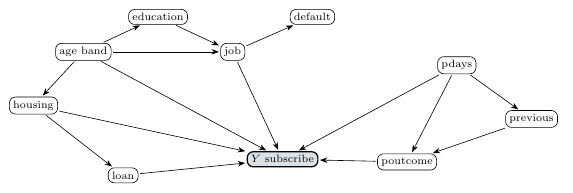

In [6]:
from src.bn import fit_bn, predict, evidence_matrix, row_evidence, verify_cgm_fitted
factors, states = fit_bn(splits["train"], M["structure"], M["alpha"], D)               # TRAIN only
print("P(Y | A, J, H, L, poutcome, pdays) · " + " · ".join(f"P({c} | {', '.join(p) or '∅'})" for c, p in M["structure"].items() if c != "y"))
print("\nvariables / cardinalities:", {v: len(s) for v, s in states.items()})
for f in factors:                                                                         # normalisation check (C-GM safeguard)
    assert np.allclose(f.values.sum(axis=-1), 1.0), f.vars
print("every CPD normalises over its child (checked)")
display(Image(filename="docs/bn_diagram.png"))

## 3 · Exp 1 — exact posteriors agree across elimination orders and clique-tree inference (tolerance 1e-6)
Elimination order changes **cost**, never the posterior. Checked three ways: (a) random tractable networks vs brute-force enumeration, (b) the fitted BN on real evidence patterns, (c) real patterns with extra synthetic masking.

In [7]:
from src.inference import random_bn, variable_elimination, CliqueTree, brute_force, OpCounter
TOL_CGM = E["tolerance_cgm"]; rows = []
for seed in range(20):
    cpds, cards = random_bn(n=8, seed=seed); rng = np.random.default_rng(1000 + seed)
    cts = {h: CliqueTree(cpds, h) for h in ("min_fill", "min_weight", "min_degree")}
    for _ in range(10):
        names = list(cards); ev_v = rng.choice(names, size=int(rng.integers(0, 4)), replace=False).tolist()
        ev = {v: int(rng.integers(cards[v])) for v in ev_v}; q = [rng.choice([v for v in names if v not in ev])]
        ref, _ = brute_force(cpds, q, ev)
        for h, ct in cts.items():
            c = OpCounter(); p, _ = variable_elimination(cpds, q, ev, h, c)
            ct.calibrate(ev); pc, _ = ct.marginal(q)
            rows.append(dict(heuristic=h, err_ve=abs(p - ref).max(), err_ct=abs(pc - ref).max(), ve_ops=c.total, ve_peak=c.peak_factor_size))
t = pd.DataFrame(rows)
display(t.groupby("heuristic").agg(n=("err_ve", "size"), max_err_ve=("err_ve", "max"), max_err_ct=("err_ct", "max"),
                                  mean_ve_ops=("ve_ops", "mean"), mean_peak=("ve_peak", "mean")))
assert max(t.err_ve.max(), t.err_ct.max()) <= TOL_CGM
print(f"(a) random networks vs enumeration: PASS (tol {TOL_CGM:g})")

cg = verify_cgm_fitted(factors, states, splits["val"], n_patterns=40)
print("(b)/(c) fitted BN, real + masked evidence:", {k: (f"{v:.1e}" if isinstance(v, float) else v) for k, v in cg.items()})
assert cg["passed"]

,n,max_err_ve,max_err_ct,mean_ve_ops,mean_peak
heuristic,,,,,
min_degree,200,1.665335e-16,1.665335e-16,255.820,54.88
min_fill,200,2.220446e-16,1.665335e-16,236.965,48.30
min_weight,200,2.220446e-16,1.665335e-16,236.965,48.30


(a) random networks vs enumeration: PASS (tol 1e-06)
(b)/(c) fitted BN, real + masked evidence: {'ve_vs_ct': '2.2e-16', 've_vs_enum': '1.1e-16', 'ct_vs_enum': '1.1e-16', 'p_evidence': '2.2e-16', 'tolerance': '1.0e-06', 'passed': True, 'n_patterns': 40}


## 4 · Graph analysis: induced cliques, elimination traces, evidence propagation
Maximum clique size / treewidth per heuristic (worst case, no evidence), then a **step-by-step trace** of the most expensive real test query under two heuristics (same posterior, different cost), and the calibrated clique tree with its two-pass sum-product message schedule.

In [8]:
from src.diagnostics import (elimination_trace, induced_graph_summary, clique_tree_tables, evidence_pattern_costs, error_vs_threshold)
show(induced_graph_summary(factors))

ex_nat = predict(splits["test"], factors, states)                                   # exact, natural evidence
i_hard = ex_nat.ops.idxmax(); row = splits["test"].loc[i_hard]
ev = row_evidence(row, states)
print("most expensive natural test query: observed =", {v: states[v][s] for v, s in ev.items()},
      "| hidden =", [v for v in states if v != "y" and v not in ev])
for h in ("min_fill", "min_degree"):
    tr, post, ops = elimination_trace(factors, ["y"], ev, h)
    print(f"\nVE trace, heuristic={h}: total ops={ops}, P(y=1|evidence)={post[1]:.4f}, max induced clique width={tr.clique_width.max()}, "
          f"largest intermediate factor={tr.product_entries.max()} entries")
    show(tr[["step", "eliminated", "bucket_size", "induced_clique", "product_entries", "new_factor_scope", "ops_step", "ops_cum"]])

ct = CliqueTree(factors, "min_fill"); cl, ed, sch = clique_tree_tables(ct)
print("\nCalibrated clique tree (min_fill): cliques"); show(cl)
print("tree edges / separators"); show(ed)
print("sum-product message schedule (collect leaves→root, then distribute root→leaves)"); show(sch)
c = ct.calibrate(ev); pc, _ = ct.marginal(["y"])
print(f"\nevidence propagation: calibrating this evidence costs {c.total} ops (peak factor {c.peak_factor_size} entries); "
      f"P(y=1|evidence)={pc[1]:.4f} equals the VE posterior {post[1]:.4f} -> {np.isclose(pc[1], post[1])}")

,heuristic,elimination_order,max_clique_size,treewidth,n_maximal_cliques,largest_clique_entries,largest_clique
0,min_fill,previous_bin -> default -> education -> job -> age_band -> housing -> loan -...,7,6,4,3888,age_band housing job loan pdays_bin poutcome y
1,min_weight,previous_bin -> default -> education -> job -> age_band -> housing -> loan -...,7,6,4,3888,age_band housing job loan pdays_bin poutcome y
2,min_degree,default -> education -> previous_bin -> age_band -> housing -> job -> loan -...,7,6,4,3888,age_band housing job loan pdays_bin poutcome y


most expensive natural test query: observed = {'age_band': '30-59', 'default': 'no', 'housing': 'no', 'loan': 'no', 'poutcome': 'failure'} | hidden = ['education', 'job', 'pdays_bin', 'previous_bin']

VE trace, heuristic=min_fill: total ops=339, P(y=1|evidence)=0.1683, max induced clique width=3, largest intermediate factor=96 entries


,step,eliminated,bucket_size,induced_clique,product_entries,new_factor_scope,ops_step,ops_cum
0,1,previous_bin,2,pdays_bin previous_bin,4,pdays_bin,6,6
1,2,education,2,education job,96,job,180,186
2,3,job,3,job pdays_bin y,48,pdays_bin y,140,326
3,4,pdays_bin,3,pdays_bin y,4,y,8,334



VE trace, heuristic=min_degree: total ops=339, P(y=1|evidence)=0.1683, max induced clique width=3, largest intermediate factor=96 entries


,step,eliminated,bucket_size,induced_clique,product_entries,new_factor_scope,ops_step,ops_cum
0,1,education,2,education job,96,job,180,180
1,2,previous_bin,2,pdays_bin previous_bin,4,pdays_bin,6,186
2,3,job,3,job pdays_bin y,48,pdays_bin y,140,326
3,4,pdays_bin,3,pdays_bin y,4,y,8,334



Calibrated clique tree (min_fill): cliques


... (2 outputs left out)

,i,j,separator,sep_entries
0,0,1,age_band job,36
1,0,2,job,12
2,1,3,pdays_bin poutcome,6


sum-product message schedule (collect leaves→root, then distribute root→leaves)


,pass_,step,sender,receiver,separator
0,collect,1,3,1,pdays_bin poutcome
1,collect,2,1,0,age_band job
2,collect,3,2,0,job
3,distribute,4,0,2,job
4,distribute,5,0,1,age_band job
5,distribute,6,1,3,pdays_bin poutcome



evidence propagation: calibrating this evidence costs 41325 ops (peak factor 3888 entries); P(y=1|evidence)=0.1683 equals the VE posterior 0.1683 -> True


## 5 · Run the full experiment pipeline on the real data
Runs the frozen scripts (`prepare_data` → `verify_inference` → `run_experiments` → `evaluate` → `make_results` → `profile_latency`). Settings are in `configs/*.yaml` and were **frozen before looking at test outcomes**: 5 seeds for every stochastic part, 1,000 block-bootstrap replicates, Holm correction for the confirmatory family. Output is cached; a changed dataset, source file or config triggers a re-run.

In [9]:
def code_stamp():
    h = hashlib.sha256()
    for f in sorted((root / "src").glob("*.py")) + sorted((root / "scripts").glob("*.py")) + sorted((root / "configs").glob("*.yaml")):
        h.update(f.read_bytes())
    return h.hexdigest()
STAMP = dict(data=prov["sha256"], code=code_stamp())
NEED = ["metrics/main_results.csv", "metrics/bootstrap.csv", "metrics/seed_aggregate.csv", "metrics/exp2_complexity.csv",
        "metrics/exp5_aggregate.csv", "metrics/latency.csv", "metrics/cgm.json", "metrics/predictive_baselines.csv",
        "metrics/group_table.csv", "logs/run_log.json", "figures/fig_complexity.png"]
def results_current():
    sp = pathlib.Path(OUT) / "logs" / "notebook_stamp.json"
    return all((pathlib.Path(OUT) / n).exists() for n in NEED) and sp.exists() and json.load(open(sp)) == STAMP

def run(cmd):
    print("\n$ python", " ".join(cmd)); t0 = time.time()
    p = subprocess.Popen([sys.executable, "-u", *cmd], cwd=root, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout: print("   ", line, end="")
    p.wait(); print(f"   [exit {p.returncode}, {time.time() - t0:.0f}s]")
    if p.returncode: raise RuntimeError(f"{cmd[0]} failed (exit {p.returncode}); see output above")

if results_current() and not FORCE_RERUN:
    print("cached results are current for this data + code + configs -> not re-running (set FORCE_RERUN=True to recompute)")
elif RUN_PIPELINE:
    for cmd in (["scripts/prepare_data.py", "configs/data.yaml"], ["scripts/verify_inference.py", "--mode", "real"],
                ["scripts/run_experiments.py", "--mode", "real", "--out", OUT],
                ["scripts/evaluate.py", "--out", OUT], ["scripts/make_results.py", "--out", OUT, "--mode", "real"],
                ["scripts/profile_latency.py", "--mode", "real", "--out", OUT]):
        run(cmd)
    json.dump(STAMP, open(f"{OUT}/logs/notebook_stamp.json", "w"))
else:
    assert results_current(), "RUN_PIPELINE=False but no current results/ found"

LOG = json.load(open(f"{OUT}/logs/run_log.json"))
assert LOG["mode"] == "real" and LOG["data_sha256"] == prov["sha256"], "results/ were not produced from this real dataset"
MET = lambda n: pd.read_csv(f"{OUT}/metrics/{n}.csv")
R, CH, GT = MET("main_results"), MET("chosen_fallbacks"), MET("group_table")
BUD = {float(k): v for k, v in LOG["budgets_ops"].items()}
print("run mode:", LOG["mode"], "| runtime (s):", LOG["runtime_s"], "| seeds:", LOG["seeds"])
print("deterministic op budgets (mult+add per query) at natural validation quantiles:", BUD)


$ python scripts/prepare_data.py configs/data.yaml
    {'train': (24712, np.float64(0.0481)), 'val': (8238, np.float64(0.1107)), 'test': (8238, np.float64(0.3083))}
   [exit 0, 1s]

$ python scripts/verify_inference.py --mode real
    C-GM PASS: n=400, max|VE-CT|=1.67e-16, tol=1e-06
   [exit 0, 1s]

$ python scripts/run_experiments.py --mode real --out results
    data {'train': 24712, 'val': 8238, 'test': 8238}
    C-GM {'natural': True, 'synthetic_dependent_mask': True}
    done main 483 s
    done ablation_no_simplification 726 s
    done robust_heuristic_min_weight 766 s
    done robust_heuristic_min_degree 807 s
    done robust_capacity_0.1 847 s
    done robust_capacity_0.3 886 s
    done robust_discretization 928 s
    done robust_structure_sparse 967 s
    done robust_structure_dense 1011 s
    finished 1307 s
   [exit 0, 1310s]

$ python scripts/evaluate.py --out results
    evaluate: bootstrap rows 26 | n_boot 1000
   [exit 0, 39s]

$ python scripts/make_results.py --out res

## 6 · Exp 2 — preprocessing cost, query cost, peak factor size and memory across evidence workloads
Workloads: **natural** evidence (real `unknown` = unobserved) and **synthetic** extra masking at 25/50/75 % (*SYNTHETIC*). Costs are factor-entry operation counts (deterministic); memory is `tracemalloc` peak for one query.

,workload,method,n_patterns,ops_mean,ops_max,peak_factor_mean,peak_factor_max,mem_peak_kb,preprocessing_ops,max_clique,n_cliques
0,natural,ve_min_fill,200,24.7,284,6.5,96,13.9,0,NaN,NaN
1,natural,ve_min_weight,200,25.1,284,6.7,96,13.9,0,NaN,NaN
2,natural,ve_min_degree,200,24.7,284,6.5,96,13.9,0,NaN,NaN
3,natural,clique_tree_min_fill,200,44789.6,45801,3888.0,3888,163.3,29337,7.0,4.0
4,natural,clique_tree_min_weight,200,44789.6,45801,3888.0,3888,163.3,29337,7.0,4.0
5,synthetic_mask_25,ve_min_fill,200,66.2,658,20.0,216,16.6,0,NaN,NaN
6,synthetic_mask_25,ve_min_weight,200,68.3,658,21.2,216,16.6,0,NaN,NaN
7,synthetic_mask_25,ve_min_degree,200,66.3,658,20.0,216,16.6,0,NaN,NaN
8,synthetic_mask_25,clique_tree_min_fill,200,43156.0,45801,3888.0,3888,163.3,29337,7.0,4.0
9,synthetic_mask_25,clique_tree_min_weight,200,43156.0,45801,3888.0,3888,163.3,29337,7.0,4.0


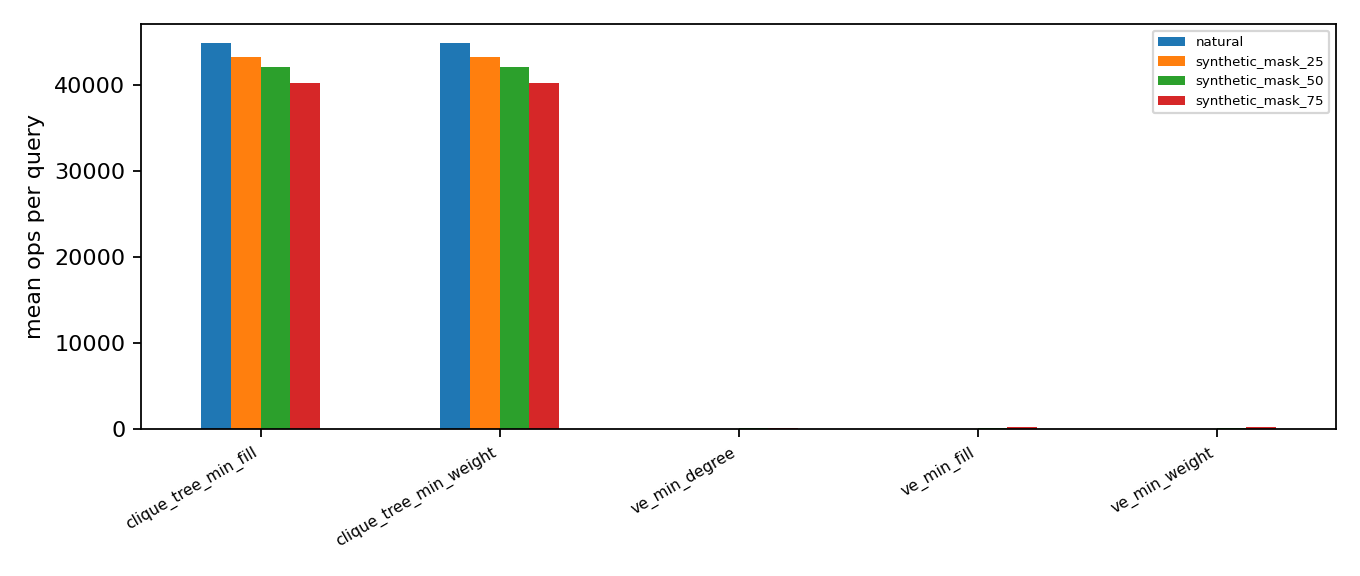

Single-marginal query on natural evidence: VE(min_fill) mean 24.7 ops, peak factor 96 entries; clique-tree calibration 44,790 ops/evidence (+29,337 one-off preprocessing), peak 3888, max clique 7 vars.
-> Clique-tree calibration answers EVERY marginal for one evidence setting; for a single P(Y|e) query VE is far cheaper. The tree only pays off when many different marginals share the same evidence (secondary question 2).

How cost grows with hidden evidence (VE):


,ops_mean,ops_max,peak_factor_mean,peak_factor_max
workload,,,,
natural,24.7,284,6.5,96
synthetic_mask_25,66.2,658,20.0,216
synthetic_mask_50,146.0,1379,44.1,432
synthetic_mask_75,227.7,1379,67.8,432


In [10]:
X2 = MET("exp2_complexity"); show(X2, 1)
fig("fig_complexity.png")
nat2 = X2[X2.workload == "natural"].set_index("method")
ve, ctm = nat2.loc[f"ve_{H}"], nat2.loc[f"clique_tree_{H}"]
print(f"Single-marginal query on natural evidence: VE({H}) mean {ve.ops_mean:.1f} ops, peak factor {ve.peak_factor_max:.0f} entries; "
      f"clique-tree calibration {ctm.ops_mean:,.0f} ops/evidence (+{ctm.preprocessing_ops:,.0f} one-off preprocessing), peak {ctm.peak_factor_max:.0f}, "
      f"max clique {ctm.max_clique:.0f} vars.\n"
      "-> Clique-tree calibration answers EVERY marginal for one evidence setting; for a single P(Y|e) query VE is far cheaper. "
      "The tree only pays off when many different marginals share the same evidence (secondary question 2).")
syn = X2[X2.method == f"ve_{H}"].set_index("workload")[["ops_mean", "ops_max", "peak_factor_mean", "peak_factor_max"]]
print("\nHow cost grows with hidden evidence (VE):"); show(syn, 1)

In [11]:
print("Which evidence patterns create the LARGEST intermediate factors? (pattern = which variables are observed; test split, min_fill)")
from src.pipeline import make_mask
top_nat, all_nat = evidence_pattern_costs(factors, states, splits["test"], None, H, top=8)
print("\nNATURAL evidence — top patterns by peak factor size"); show(top_nat)
mt_dep = make_mask(splits["test"], C, bl, "dependent", 0, 1)
top_dep, all_dep = evidence_pattern_costs(factors, states, splits["test"], mt_dep, H, top=8)
print("\nSYNTHETIC dependent mask (young customers hide more variables) — top patterns by peak factor size"); show(top_dep)
corr = all_nat[["n_observed", "ops"]].corr().iloc[0, 1]
print(f"\ncorrelation(#observed variables, ops) over natural patterns = {corr:+.2f}: "
      "cost depends on WHICH evidence is hidden, and that is what an operation budget trips on.")

Which evidence patterns create the LARGEST intermediate factors? (pattern = which variables are observed; test split, min_fill)

NATURAL evidence — top patterns by peak factor size


,observed,hidden,n_observed,n_queries,ops,peak_factor_entries
0,age_band default housing loan poutcome,education job pdays_bin previous_bin,5,1,339,96
1,age_band housing loan pdays_bin poutcome,education job default previous_bin,5,1,284,96
2,age_band housing loan pdays_bin previous_bin poutcome,education job default,6,4,282,96
3,age_band default housing loan pdays_bin poutcome,education job previous_bin,6,2,260,96
4,age_band default housing loan pdays_bin previous_bin poutcome,education job,7,12,258,96
5,age_band education default housing loan poutcome,job pdays_bin previous_bin,6,1,124,48
6,age_band education job default poutcome,housing loan pdays_bin previous_bin,5,6,97,36
7,age_band education job default previous_bin poutcome,housing loan pdays_bin,6,4,93,36



SYNTHETIC dependent mask (young customers hide more variables) — top patterns by peak factor size


,observed,hidden,n_observed,n_queries,ops,peak_factor_entries
0,age_band poutcome,education job default housing loan pdays_bin previous_bin,2,2,1558,432
1,age_band previous_bin poutcome,education job default housing loan pdays_bin,3,1,1554,432
2,age_band default poutcome,education job housing loan pdays_bin previous_bin,3,1,1534,432
3,age_band education poutcome,job default housing loan pdays_bin previous_bin,3,1,1379,432
4,age_band education default poutcome,job housing loan pdays_bin previous_bin,4,1,935,432
5,age_band education default previous_bin poutcome,job housing loan pdays_bin,5,1,931,432
6,age_band pdays_bin poutcome,education job default housing loan previous_bin,3,2,885,216
7,age_band pdays_bin previous_bin poutcome,education job default housing loan,4,13,883,216



correlation(#observed variables, ops) over natural patterns = -0.43: cost depends on WHICH evidence is hidden, and that is what an operation budget trips on.


## 7 · Exp 3 — controlled operation budgets: approximation error, fallback rate and decisions by group
A query **trips** iff exact elimination would exceed the budget (counted in factor-entry multiplications + additions); a precomputed fallback table then answers it. Budgets are quantiles of the *natural* validation op-count distribution. `natural` = real missingness only; `dependent` = **SYNTHETIC** extra masking, heavier for the youngest band; `independent` = **SYNTHETIC** matched control with the same overall masking rate but no group dependence.

In [12]:
MCOLS = ["ap", "auroc", "balanced_acc", "dEOpp_supported", "dEOpp", "dDP", "dEOdds", "sel_ratio", "fallback_rate", "fallback_gap",
         "worst_group_flip", "agree_exact", "tv_mean", "tv_max", "log_loss", "brier"]
RM = R[(R.tag == "main") & np.isclose(R.q, PQ)]
def agg(df, cols=MCOLS, by=("workload", "method")):
    g = df.groupby(list(by))[cols]
    out = g.mean().add_suffix("")
    out["n_seeds"] = df.groupby(list(by)).seed.nunique()
    return out
A = agg(RM)
core = ["exact", "global_prior", "proposed", "proposed_unaware", "util_sel", "thr_adj_post_budget", "fair_exact"]
nd = sorted(set(BUD.values()))
print(f"Budget grid (natural validation op-count quantiles -> ops): {BUD}  | {len(nd)} distinct budgets out of {len(BUD)} quantiles "
      "(op counts are small integers, so neighbouring quantiles can coincide — duplicates give identical results by construction).")
print(f"Primary budget q={PQ} -> {BUD[PQ]} ops. Mean over seeds (natural workload has no stochastic part -> 1 run).")
for w in ("natural", "dependent", "independent"):
    print(f"\n=== workload: {w}" + ("" if w == "natural" else "  (SYNTHETIC masks)"))
    show(A.loc[w].loc[[m for m in core if m in A.loc[w].index], ["n_seeds", "fallback_rate", "fallback_gap", "worst_group_flip", "agree_exact",
                                                                "tv_mean", "tv_max", "log_loss", "brier"]])

Budget grid (natural validation op-count quantiles -> ops): {0.5: 11, 0.75: 11, 0.9: 11, 0.95: 25, 0.97: 26, 0.99: 52, 1.0: 258}  | 5 distinct budgets out of 7 quantiles (op counts are small integers, so neighbouring quantiles can coincide — duplicates give identical results by construction).
Primary budget q=0.75 -> 11 ops. Mean over seeds (natural workload has no stochastic part -> 1 run).

=== workload: natural


,n_seeds,fallback_rate,fallback_gap,worst_group_flip,agree_exact,tv_mean,tv_max,log_loss,brier
method,,,,,,,,,
exact,1,0.000,0.000,0.000,1.000,0.000,0.000,0.709,0.223
global_prior,1,0.201,0.222,0.303,0.850,0.058,0.612,0.852,0.260
proposed,1,0.201,0.222,0.038,0.983,0.008,0.378,0.710,0.223
proposed_unaware,1,0.201,0.222,0.038,0.983,0.008,0.378,0.710,0.223
util_sel,1,0.201,0.222,0.198,0.878,0.053,0.616,0.825,0.254
thr_adj_post_budget,1,0.201,0.222,0.319,0.819,0.058,0.612,0.852,0.260
fair_exact,1,0.000,0.000,0.000,1.000,0.000,0.000,0.709,0.223



=== workload: dependent  (SYNTHETIC masks)


,n_seeds,fallback_rate,fallback_gap,worst_group_flip,agree_exact,tv_mean,tv_max,log_loss,brier
method,,,,,,,,,
exact,5,0.000,0.000,0.000,1.000,0.000,0.000,0.704,0.222
global_prior,5,0.574,0.462,0.473,0.736,0.098,0.612,0.888,0.266
proposed,5,0.574,0.462,0.298,0.848,0.068,0.548,0.788,0.242
proposed_unaware,5,0.574,0.462,0.134,0.957,0.036,0.431,0.703,0.218
util_sel,5,0.574,0.462,0.402,0.775,0.090,0.616,0.844,0.258
thr_adj_post_budget,5,0.574,0.462,0.618,0.706,0.098,0.612,0.888,0.266
fair_exact,5,0.000,0.000,0.000,1.000,0.000,0.000,0.704,0.222



=== workload: independent  (SYNTHETIC masks)


,n_seeds,fallback_rate,fallback_gap,worst_group_flip,agree_exact,tv_mean,tv_max,log_loss,brier
method,,,,,,,,,
exact,5,0.000,0.00,0.000,1.000,0.000,0.000,0.704,0.222
global_prior,5,0.621,0.17,0.572,0.720,0.099,0.612,0.897,0.269
proposed,5,0.621,0.17,0.267,0.840,0.063,0.550,0.794,0.245
proposed_unaware,5,0.621,0.17,0.187,0.949,0.023,0.436,0.707,0.221
util_sel,5,0.621,0.17,0.324,0.765,0.090,0.616,0.853,0.261
thr_adj_post_budget,5,0.621,0.17,0.548,0.677,0.099,0.612,0.897,0.269
fair_exact,5,0.000,0.00,0.000,1.000,0.000,0.000,0.704,0.222


Fallback rate and decision change vs exact, by age×marital group (primary budget, seed 0). Red/flagged = exploratory (<30 positives).

--- natural


,,,,fallback_rate:global_prior,fallback_rate:proposed,flip:global_prior,flip:proposed,tpr:global_prior,tpr:proposed
group,n,pos,exploratory,,,,,,
30-59|married,3152,932,False,0.176,0.176,0.122,0.019,0.212,0.468
30-59|single,1631,451,False,0.169,0.169,0.114,0.018,0.169,0.406
<30|single,1525,502,False,0.246,0.246,0.198,0.005,0.277,0.582
>=60|married,659,309,False,0.337,0.337,0.303,0.038,0.421,0.783
30-59|divorced,650,176,False,0.177,0.177,0.103,0.015,0.239,0.489
<30|married,384,79,False,0.115,0.115,0.083,0.003,0.291,0.468
>=60|divorced,160,70,False,0.294,0.294,0.275,0.019,0.471,0.829
<30|divorced,34,6,True,0.118,0.118,0.059,0.000,0.000,0.167
>=60|single,25,8,True,0.360,0.360,0.360,0.120,0.375,0.875



--- dependent  (SYNTHETIC masks)


,,,,fallback_rate:global_prior,fallback_rate:proposed,flip:global_prior,flip:proposed,tpr:global_prior,tpr:proposed
group,n,pos,exploratory,,,,,,
30-59|married,3152,932,False,0.450,0.450,0.189,0.189,0.144,0.144
30-59|single,1631,451,False,0.475,0.475,0.182,0.182,0.111,0.111
<30|single,1525,502,False,0.890,0.890,0.400,0.400,0.046,0.046
>=60|married,659,309,False,0.578,0.578,0.478,0.100,0.288,0.913
30-59|divorced,650,176,False,0.482,0.482,0.186,0.186,0.170,0.170
<30|married,384,79,False,0.901,0.901,0.331,0.331,0.013,0.013
>=60|divorced,160,70,False,0.531,0.531,0.412,0.119,0.343,0.957
<30|divorced,34,6,True,0.794,0.794,0.294,0.294,0.000,0.000
>=60|single,25,8,True,0.640,0.640,0.520,0.120,0.125,0.875


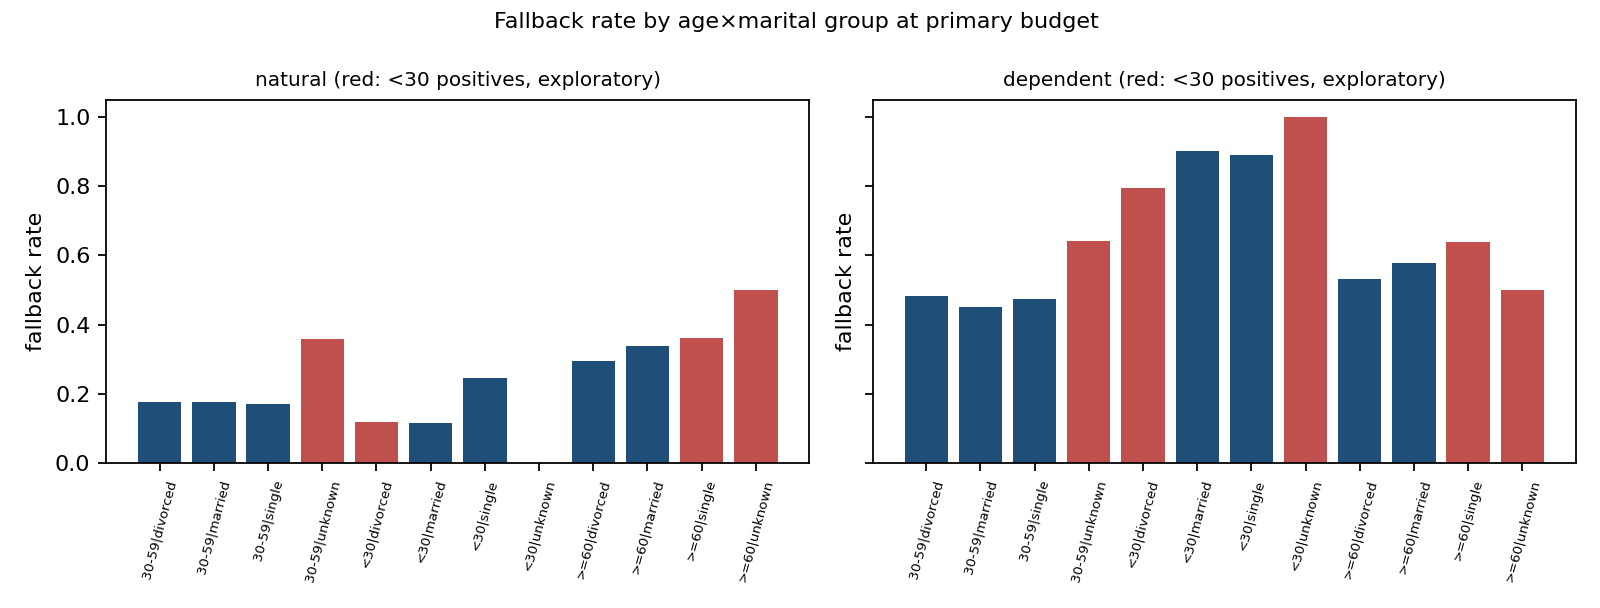

In [13]:
print("Fallback rate and decision change vs exact, by age×marital group (primary budget, seed 0). Red/flagged = exploratory (<30 positives).")
g = GT[GT.method.isin(["global_prior", "proposed"])].copy()
g["exploratory"] = g.pos < MS
for w in ("natural", "dependent"):
    x = g[g.workload == w].pivot_table(index=["group", "n", "pos", "exploratory"], columns="method", values=["fallback_rate", "flip", "tpr"])
    x.columns = [f"{a}:{b}" for a, b in x.columns]
    print(f"\n--- {w}" + ("  (SYNTHETIC masks)" if w != "natural" else "")); show(x.sort_index(level="n", ascending=False))
fig("fig_group_fallback.png")

In [14]:
print("Probabilistic error vs the exact posterior (binary => total-variation distance = |p - p_exact|), seed 0, primary budget")
GD = group_denominators(splits["test"], MS).set_index("group")
rows, grows = [], []
for w in ("natural", "dependent"):
    Z = np.load(f"{OUT}/runs/artifacts_{w}.npz", allow_pickle=True); pe = Z["score_exact"]
    for m in ("global_prior", "proposed", "proposed_unaware", "util_sel"):
        err = np.abs(Z[f"score_{m}"] - pe)
        rows.append(dict(workload=w, method=m, max_marginal_error=err.max(), mean_TV=err.mean(),
                         mean_TV_on_fallback_queries=err[Z[f"fb_{m}"].astype(bool)].mean() if Z[f"fb_{m}"].any() else np.nan))
        s = pd.Series(err).groupby(Z["group"]).mean().rename("groupwise_mean_marginal_error")
        grows.append(s.reset_index().rename(columns={"index": "group"}).assign(workload=w, method=m))
show(pd.DataFrame(rows), 4)
ge = pd.concat(grows); ge["pos"] = ge["group"].map(GD.pos); ge["exploratory"] = ge.pos < MS
print("\ngroupwise mean marginal error (largest first; exploratory groups flagged)")
show(ge[ge.workload == "dependent"].pivot_table(index=["group", "pos", "exploratory"], columns="method", values="groupwise_mean_marginal_error").sort_values("global_prior", ascending=False), 4)
print("log loss and Brier (per method, above) are computed on the budgeted probabilities; AUROC / AP / balanced accuracy in §8.")

Probabilistic error vs the exact posterior (binary => total-variation distance = |p - p_exact|), seed 0, primary budget


,workload,method,max_marginal_error,mean_TV,mean_TV_on_fallback_queries
0,natural,global_prior,0.6124,0.0582,0.2899
1,natural,proposed,0.3778,0.0080,0.0399
2,natural,proposed_unaware,0.3778,0.0080,0.0399
3,natural,util_sel,0.6159,0.0532,0.2652
4,dependent,global_prior,0.6124,0.0968,0.1687
5,dependent,proposed,0.6159,0.0890,0.1550
6,dependent,proposed_unaware,0.3658,0.0359,0.0625
7,dependent,util_sel,0.6159,0.0890,0.1550



groupwise mean marginal error (largest first; exploratory groups flagged)


,,method,global_prior,proposed,proposed_unaware,util_sel
group,pos,exploratory,,,,
<30|unknown,1,True,0.4022,0.3854,0.0976,0.3854
>=60|unknown,1,True,0.2229,0.1427,0.1314,0.1427
>=60|married,309,False,0.1775,0.1141,0.0727,0.1141
<30|single,502,False,0.1760,0.1687,0.0645,0.1687
>=60|single,8,True,0.1644,0.1110,0.0639,0.1110
>=60|divorced,70,False,0.1614,0.1061,0.0632,0.1061
<30|married,79,False,0.1439,0.1387,0.0651,0.1387
<30|divorced,6,True,0.1382,0.1317,0.0776,0.1317
30-59|unknown,5,True,0.1356,0.1363,0.0314,0.1363


log loss and Brier (per method, above) are computed on the budgeted probabilities; AUROC / AP / balanced accuracy in §8.


Budget–accuracy–fairness curves (mean ± 95% t-interval over seeds; budgets = natural validation op quantiles)


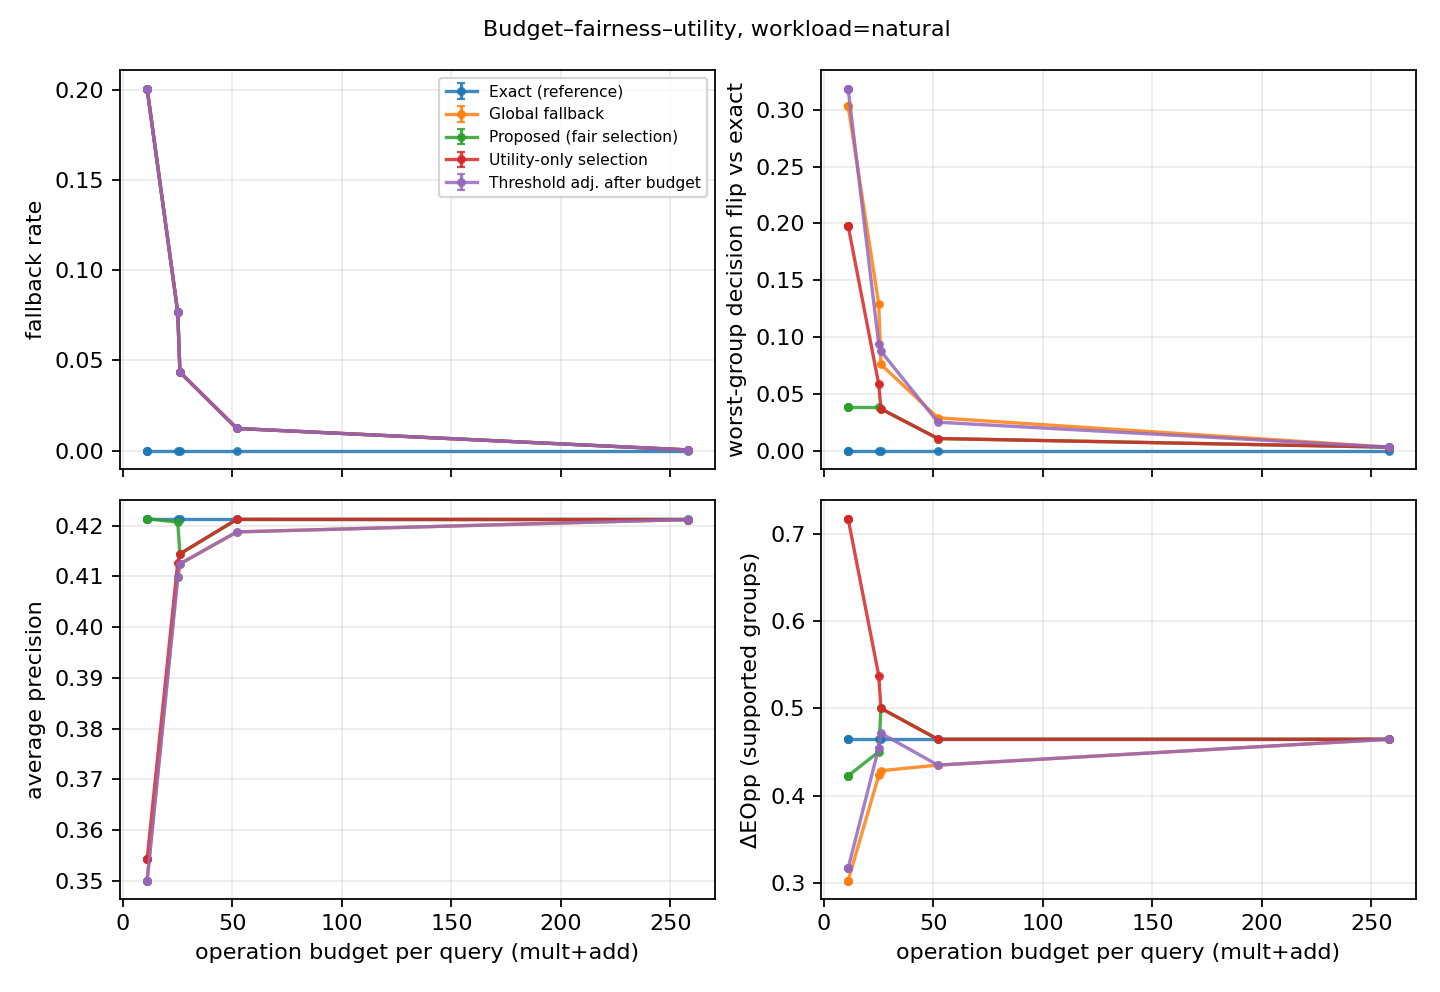

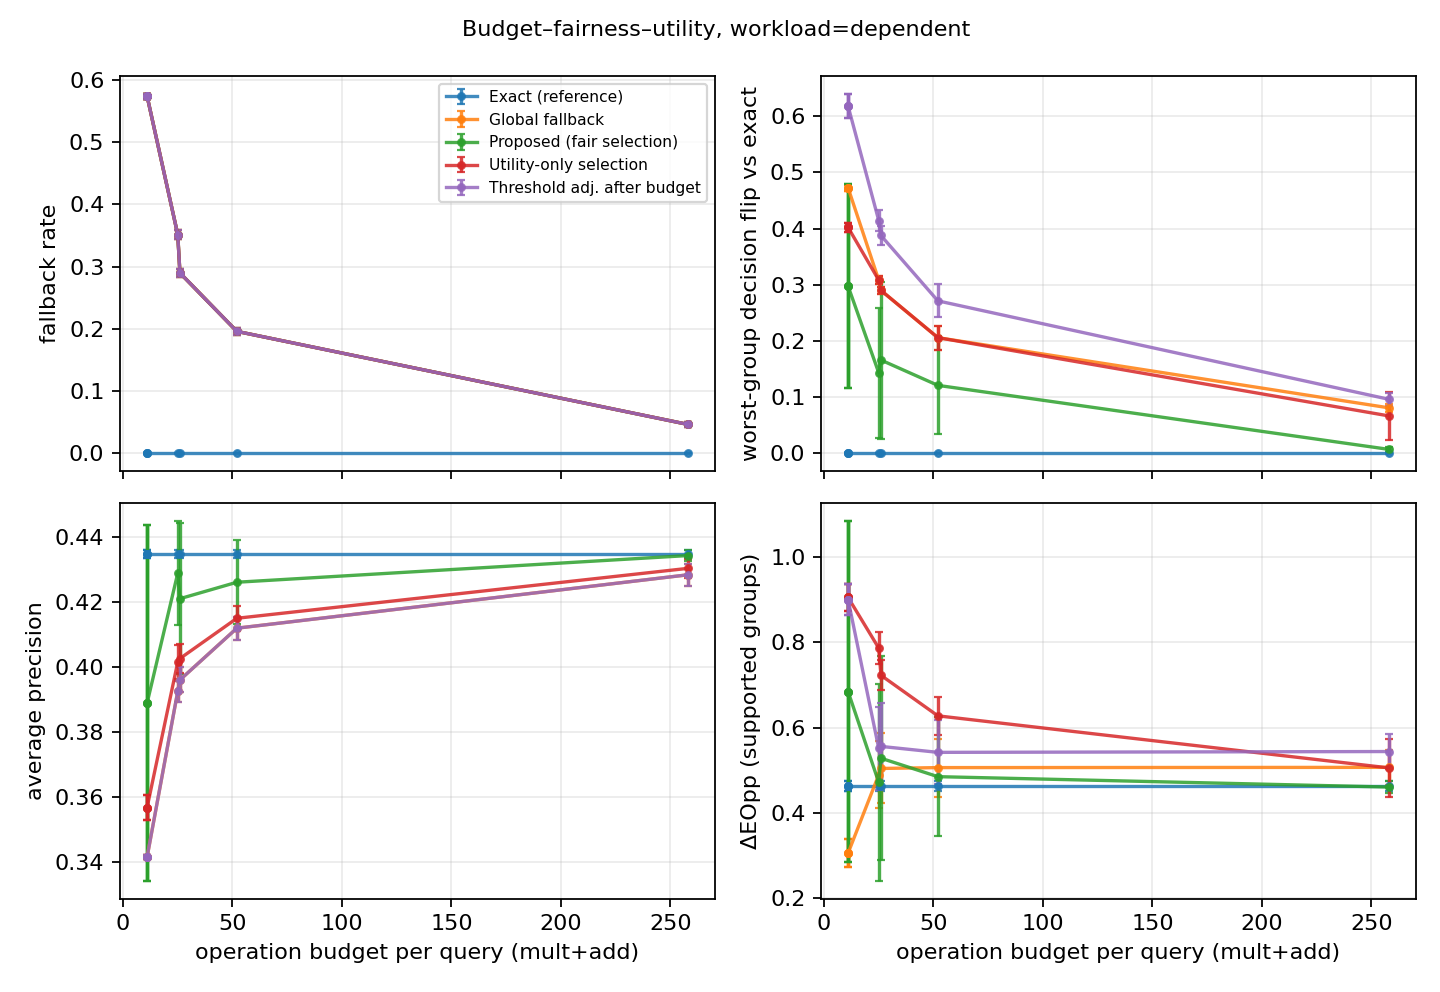

In [15]:
print("Budget–accuracy–fairness curves (mean ± 95% t-interval over seeds; budgets = natural validation op quantiles)")
fig("fig_budget_curves_natural.png"); fig("fig_budget_curves_dependent.png")

## 8 · Exp 4 — proposed fallback vs equal-budget alternatives at matched utility
**Proposed rule (frozen).** Among candidate fallbacks with *validation* AP loss ≤ 0.01 pick the one with the smallest worst-group decision-flip rate vs exact; routing itself uses only evidence-pattern/op-count information. `proposed_unaware` is the same rule restricted to fallbacks that **never** condition on the protected attribute (the required group-unaware routing comparison). `util_sel` (utility-only selection), `global_prior` (one global fallback), `thr_adj_post_budget` (Hardt-style threshold adjustment after budgeted inference; **needs the group label at decision time**) and `fair_exact` (fairness-adjusted exact rule; also needs it) are the baselines/ablations.

In [16]:
def matched_utility(w):
    a = A.loc[w].copy(); ap_ex = a.loc["exact", "ap"]
    a["ap_loss_vs_exact"] = ap_ex - a["ap"]; a["within_utility_tol"] = a.ap_loss_vs_exact <= TOL
    return a
for w in ("natural", "dependent"):
    a = matched_utility(w)
    print(f"\n=== {w}" + ("" if w == "natural" else "  (SYNTHETIC masks)") + f"  — primary budget {BUD[PQ]} ops, capacity {C['capacity']:.0%}")
    show(a.loc[[m for m in core if m in a.index], ["ap", "ap_loss_vs_exact", "within_utility_tol", "auroc", "balanced_acc", "dEOpp_supported", "dDP", "dEOdds",
                                                  "worst_group_flip", "agree_exact", "fallback_rate"]])
uses = R[(R.tag == "main") & np.isclose(R.q, PQ)].groupby("method").group_label_at_decision.max()
print("\nmethods that use the protected attribute / group label at decision time in at least one run:",
      sorted(uses[uses].index.tolist()))
print("\nWhich fallback did each rule pick? (primary budget)")
ch = CH[(CH.tag == "main") & np.isclose(CH.q, PQ)]
for col in ("proposed", "proposed_unaware", "util_sel"):
    print(col); show(ch.groupby("workload")[col].value_counts().unstack(fill_value=0))


=== natural  — primary budget 11 ops, capacity 20%


,ap,ap_loss_vs_exact,within_utility_tol,auroc,balanced_acc,dEOpp_supported,dDP,dEOdds,worst_group_flip,agree_exact,fallback_rate
method,,,,,,,,,,,
exact,0.421,0.000,True,0.623,0.603,0.465,0.715,0.833,0.000,1.000,0.000
global_prior,0.350,0.071,False,0.549,0.515,0.303,0.857,1.000,0.303,0.850,0.201
proposed,0.421,-0.000,True,0.623,0.601,0.423,0.697,0.833,0.038,0.983,0.201
proposed_unaware,0.421,-0.000,True,0.623,0.601,0.423,0.697,0.833,0.038,0.983,0.201
util_sel,0.354,0.067,False,0.551,0.537,0.717,0.857,1.000,0.198,0.878,0.201
thr_adj_post_budget,0.350,0.071,False,0.549,0.505,0.317,0.857,1.000,0.319,0.819,0.201
fair_exact,0.421,0.000,True,0.623,0.598,0.465,0.715,0.833,0.000,1.000,0.000



=== dependent  (SYNTHETIC masks)  — primary budget 11 ops, capacity 20%


,ap,ap_loss_vs_exact,within_utility_tol,auroc,balanced_acc,dEOpp_supported,dDP,dEOdds,worst_group_flip,agree_exact,fallback_rate
method,,,,,,,,,,,
exact,0.435,0.000,True,0.626,0.601,0.463,0.708,0.867,0.000,1.000,0.000
global_prior,0.342,0.093,False,0.535,0.512,0.305,0.444,0.757,0.473,0.736,0.574
proposed,0.389,0.046,False,0.577,0.560,0.684,0.862,0.967,0.298,0.848,0.574
proposed_unaware,0.438,-0.003,True,0.627,0.594,0.336,0.669,0.900,0.134,0.957,0.574
util_sel,0.357,0.078,False,0.543,0.538,0.905,0.994,1.000,0.402,0.775,0.574
thr_adj_post_budget,0.342,0.093,False,0.535,0.505,0.900,0.912,0.923,0.618,0.706,0.574
fair_exact,0.435,0.000,True,0.626,0.598,0.469,0.718,0.867,0.000,1.000,0.000



methods that use the protected attribute / group label at decision time in at least one run: ['cand_age_prior', 'fair_exact', 'proposed', 'thr_adj_post_budget', 'util_sel']

Which fallback did each rule pick? (primary budget)
proposed


proposed,age_prior,blanket_medium,blanket_small
workload,,,
dependent,3,0,2
independent,3,2,0
natural,0,1,0


proposed_unaware


proposed_unaware,blanket_medium,blanket_small
workload,,
dependent,0,5
independent,5,0
natural,1,0


util_sel


util_sel,age_prior
workload,
dependent,5
independent,5
natural,1


In [17]:
print("Predictive baselines on the SAME pre-contact variables (logistic regression, gradient-boosted trees) vs the exact BN; mean over seeds")
PB = MET("predictive_baselines")
show(PB.groupby("method")[["ap", "auroc", "balanced_acc", "recall_at_capacity", "dEOpp_supported", "dDP", "dEOdds", "agree_exact", "log_loss", "brier"]].mean())
print("(decisions use the same validation-fixed top-20% threshold rule; 'agree_exact' = agreement with the exact-BN decisions)")

Predictive baselines on the SAME pre-contact variables (logistic regression, gradient-boosted trees) vs the exact BN; mean over seeds


,ap,auroc,balanced_acc,recall_at_capacity,dEOpp_supported,dDP,dEOdds,agree_exact,log_loss,brier
method,,,,,,,,,,
bn_exact,0.421,0.623,0.603,0.526,0.465,0.715,0.833,1.000,0.709,0.223
gbt,0.344,0.536,0.532,0.347,0.624,0.813,0.970,0.623,0.950,0.278
logreg,0.525,0.668,0.620,0.585,0.528,0.770,1.000,0.690,0.843,0.261


(decisions use the same validation-fixed top-20% threshold rule; 'agree_exact' = agreement with the exact-BN decisions)


## 9 · Statistical validation — paired block bootstrap and Holm correction
Resampling unit = **contiguous date-ordered blocks of the test set** (moving-block bootstrap, block length 50, 1,000 replicates). Customer IDs are absent, so **dependence from repeated customers cannot be controlled** — intervals describe *evaluation* uncertainty of fixed models only, and seeds measure algorithmic (mask) variability, not population sampling. The statistic is ΔEOpp over **supported** groups (≥ 30 positives in the full test sample, fixed once) — exactly the `dEOpp_supported` reported everywhere. The earlier notebook bootstrapped over all groups including tiny ones (n = 2), which dominated the interval; the all-groups version is kept below as a labelled sensitivity.

In [18]:
B = MET("bootstrap")
print(f"test n={int(B.n_test.dropna().iloc[0])}, block length={int(B.block_len.iloc[0])}, replicates={int(B.n_boot.min())}, alpha=0.05")
cols = ["workload", "comparison", "estimate", "lo", "hi", "p_two_sided", "p_holm", "n_groups_used"]
print("\nCONFIRMATORY family (natural workload, dEOpp, Holm-corrected): proposed − comparator, negative = proposed fairer")
show(B[B.kind == "proposed_minus_comparator"].query("confirmatory")[cols])
print("\nEXPLORATORY: dependent workload (SYNTHETIC masks), same comparisons (not in the confirmatory family)")
show(B[(B.kind == "proposed_minus_comparator") & (B.workload == "dependent")][cols])
print("\nEXPLORATORY: group-unaware routing")
show(B[B.kind == "exploratory_unaware"][cols])
print("\nDegradation of each method vs exact (ΔEOpp_method − ΔEOpp_exact)")
show(B[B.kind == "degradation_vs_exact"][cols])
print("\nSENSITIVITY: all groups incl. exploratory ones (tiny cells make this noisy)")
show(B[B.kind == "sensitivity_all_groups"][cols])
print("\nWorkload contrast (dependent − independent, SYNTHETIC masks; mean ± 95% t-interval over seeds) at the primary budget")
WC = MET("workload_contrast"); show(WC[np.isclose(WC.q, PQ) & WC.method.isin(["global_prior", "proposed", "proposed_unaware", "util_sel"])])

test n=8238, block length=50, replicates=1000, alpha=0.05

CONFIRMATORY family (natural workload, dEOpp, Holm-corrected): proposed − comparator, negative = proposed fairer


,workload,comparison,estimate,lo,hi,p_two_sided,p_holm,n_groups_used
0,natural,proposed - global_prior,0.120,0.015,0.226,0.018,0.036,7
2,natural,proposed - util_sel,-0.294,-0.370,-0.210,0.002,0.006,7
4,natural,proposed - thr_adj_post_budget,0.106,-0.006,0.251,0.080,0.080,7



EXPLORATORY: dependent workload (SYNTHETIC masks), same comparisons (not in the confirmatory family)


,workload,comparison,estimate,lo,hi,p_two_sided,p_holm,n_groups_used
13,dependent,proposed - global_prior,0.614,0.500,0.698,0.002,NaN,7
15,dependent,proposed - util_sel,0.000,0.000,0.000,1.000,NaN,7
17,dependent,proposed - thr_adj_post_budget,0.022,-0.033,0.074,0.442,NaN,7



EXPLORATORY: group-unaware routing


,workload,comparison,estimate,lo,hi,p_two_sided,p_holm,n_groups_used
6,natural,proposed_unaware - proposed,0.000,0.000,0.000,1.000,NaN,7
7,natural,proposed_unaware - global_prior,0.120,0.012,0.229,0.024,NaN,7
19,dependent,proposed_unaware - proposed,-0.609,-0.685,-0.489,0.002,NaN,7
20,dependent,proposed_unaware - global_prior,0.006,-0.088,0.132,0.707,NaN,7


... (2 outputs left out)


SENSITIVITY: all groups incl. exploratory ones (tiny cells make this noisy)


,workload,comparison,estimate,lo,hi,p_two_sided,p_holm,n_groups_used
1,natural,proposed - global_prior,-0.167,-0.385,0.554,1.000,NaN,12
3,natural,proposed - util_sel,-0.167,-0.400,0.000,1.000,NaN,12
5,natural,proposed - thr_adj_post_budget,-0.167,-0.385,0.529,1.000,NaN,12
14,dependent,proposed - global_prior,0.657,0.516,0.720,0.006,NaN,12
16,dependent,proposed - util_sel,0.000,0.000,0.000,1.000,NaN,12
18,dependent,proposed - thr_adj_post_budget,0.078,-0.027,0.097,0.316,NaN,12



Workload contrast (dependent − independent, SYNTHETIC masks; mean ± 95% t-interval over seeds) at the primary budget


,q,method,n_seeds,fallback_gap_diff_mean,fallback_gap_diff_lo,fallback_gap_diff_hi,worst_group_flip_diff_mean,worst_group_flip_diff_lo,worst_group_flip_diff_hi,dEOpp_supported_diff_mean,dEOpp_supported_diff_lo,dEOpp_supported_diff_hi,ap_diff_mean,ap_diff_lo,ap_diff_hi
15,0.75,global_prior,5,0.292,0.203,0.381,-0.100,-0.119,-0.081,0.121,0.096,0.146,0.010,0.007,0.014
16,0.75,proposed,5,0.292,0.203,0.381,0.030,-0.056,0.117,0.036,0.005,0.066,0.003,-0.003,0.010
17,0.75,proposed_unaware,5,0.292,0.203,0.381,-0.053,-0.065,-0.041,0.026,0.000,0.052,-0.001,-0.004,0.002
19,0.75,util_sel,5,0.292,0.203,0.381,0.079,0.070,0.087,0.038,0.012,0.064,0.007,0.004,0.010


## 10 · Required ablations
(A1) remove fairness-aware fallback selection → `util_sel` · (A2) one global fallback → `global_prior` · (A3) disable evidence-based (barren-node) simplification · (A4) generous budgets approximating unrestricted inference.

In [19]:
mets = ["fallback_rate", "ap", "dEOpp_supported", "worst_group_flip", "agree_exact"]
rows = []
for w in ("natural", "dependent"):
    base = R[(R.tag == "main") & np.isclose(R.q, PQ) & (R.workload == w)]
    nosimp = R[(R.tag == "ablation_no_simplification") & np.isclose(R.q, PQ) & (R.workload == w)]
    gen = R[(R.tag == "main") & np.isclose(R.q, 1.0) & (R.workload == w)]
    for label, df, meth in (("full proposed (reference)", base, "proposed"), ("A1 no fairness-aware selection", base, "util_sel"),
                            ("A2 one global fallback", base, "global_prior"), ("A3 simplification OFF (proposed)", nosimp, "proposed"),
                            ("A3 simplification OFF (global fallback)", nosimp, "global_prior"),
                            ("A4 generous budget q=1.0 (proposed)", gen, "proposed"), ("A4 generous budget q=1.0 (global fallback)", gen, "global_prior")):
        d = df[df.method == meth]
        rows.append(dict(workload=w, ablation=label, budget_ops=d.budget_ops.mean(), n_seeds=d.seed.nunique(), **{k: d[k].mean() for k in mets}))
show(pd.DataFrame(rows).set_index(["workload", "ablation"]))
print("A4: the q=1.0 budget equals the largest natural validation op count, so with natural evidence almost no query trips and the "
      "fairness gap should collapse toward the exact reference — the gap is a budget effect, not a model effect.")

budget_ops  n_seeds  fallback_rate     ap  dEOpp_supported  worst_group_flip  agree_exact
workload  ablation                                                                                                                             
natural   full proposed (reference)                         11.0        1          0.201  0.421            0.423             0.038        0.983
          A1 no fairness-aware selection                    11.0        1          0.201  0.354            0.717             0.198        0.878
          A2 one global fallback                            11.0        1          0.201  0.350            0.303             0.303        0.850
          A3 simplification OFF (proposed)                  11.0        1          0.262  0.356            0.722             0.206        0.865
          A3 simplification OFF (global fallback)           11.0        1          0.262  0.347            0.264             0.350        0.834
          A4 generous budget q=1.0 (proposed)              258.0        1          0.000  0.421            0.465             0.003        1.000
          A4 generous budget q=1.0 (global fallback)       258.0        1          0.000  0.421            0.465             0.003        1.000
dependent full proposed (reference)                         11.0        5          0.574  0.389            0.684             0.298        0.848
          A1 no fairness-aware selection                    11.0        5          0.574  0.357            0.905             0.402        0.775
          A2 one global fallback                            11.0        5          0.574  0.342            0.305             0.473        0.736
          A3 simplification OFF (proposed)                  11.0        5          0.654  0.373            0.805             0.368        0.795
          A3 simplification OFF (global fallback)           11.0        5          0.654  0.335            0.262             0.531        0.714
          A4 generous budget q=1.0 (proposed)              258.0        5          0.047  0.434            0.460             0.007        0.999
          A4 generous budget q=1.0 (global fallback)       258.0        5          0.047  0.428            0.506             0.081        0.977

A4: the q=1.0 budget equals the largest natural validation op count, so with natural evidence almost no query trips and the fairness gap should collapse toward the exact reference — the gap is a budget effect, not a model effect.


## 11 · Required robustness tests
Elimination orders · network densities · discretisations · operation budgets · evidence masks · decision thresholds (capacity). All use **all 5 seeds**.

In [20]:
robust_meth = ["exact", "global_prior", "proposed", "proposed_unaware", "util_sel", "thr_adj_post_budget"]
RR = R[R.method.isin(robust_meth)]
sel = RR[(np.isclose(RR.q, PQ)) & (RR.tag.str.startswith("robust_") | (RR.tag == "main"))]
for metric in ("dEOpp_supported", "worst_group_flip", "fallback_rate", "ap"):
    t = sel.groupby(["workload", "tag", "method"])[metric].mean().unstack("method")[[m for m in robust_meth if m in sel.method.unique()]]
    t["budget_ops"] = sel.groupby(["workload", "tag"]).budget_ops.mean()
    print(f"\n--- {metric}   (R1 robust_heuristic_*, R2 robust_structure_*, R3 robust_discretization, R6 robust_capacity_*)"); show(t.loc[["natural", "dependent"]])
print("\n--- R4 operation budgets & R5 evidence masks: full sweep (main run; workloads natural / dependent / independent)")
sw = R[(R.tag == "main") & R.method.isin(["global_prior", "proposed", "util_sel"])].groupby(["workload", "q", "budget_ops", "method"])[["fallback_gap", "worst_group_flip", "dEOpp_supported", "ap"]].mean()
show(sw.unstack("method"))


--- dEOpp_supported   (R1 robust_heuristic_*, R2 robust_structure_*, R3 robust_discretization, R6 robust_capacity_*)


method                                 exact  global_prior  proposed  proposed_unaware  util_sel  thr_adj_post_budget  budget_ops
workload  tag                                                                                                                    
natural   main                         0.465         0.303     0.423             0.423     0.717                0.317        11.0
          robust_capacity_0.1          0.339         0.165     0.284             0.284     0.586                0.157        11.0
          robust_capacity_0.3          0.525         0.362     0.491             0.491     0.776                0.326        11.0
          robust_discretization        0.165         0.265     0.149             0.149     0.149                0.283        11.0
          robust_heuristic_min_degree  0.465         0.303     0.423             0.423     0.717                0.317        11.0
          robust_heuristic_min_weight  0.465         0.303     0.423             0.423     0.717                0.317        11.0
          robust_structure_dense       0.498         0.276     0.739             0.409     0.739                0.332        11.0
          robust_structure_sparse      0.561         0.617     0.794             0.535     0.535                0.647        11.0
dependent main                         0.463         0.305     0.684             0.336     0.905                0.900        11.0
          robust_capacity_0.1          0.341         0.170     0.250             0.250     0.788                0.430        11.0
          robust_capacity_0.3          0.527         0.364     0.418             0.418     0.964                0.833        11.0
          robust_discretization        0.169         0.175     0.140             0.140     0.175                0.954        11.0
          robust_heuristic_min_degree  0.463         0.305     0.684             0.336     0.905                0.900        11.0
          robust_heuristic_min_weight  0.463         0.305     0.684             0.336     0.905                0.900        11.0
          robust_structure_dense       0.529         0.265     0.931             0.306     0.931                0.879        11.0
          robust_structure_sparse      0.657         0.400     0.909             0.437     0.484                0.372        11.0


--- worst_group_flip   (R1 robust_heuristic_*, R2 robust_structure_*, R3 robust_discretization, R6 robust_capacity_*)


method                                 exact  global_prior  proposed  proposed_unaware  util_sel  thr_adj_post_budget  budget_ops
workload  tag                                                                                                                    
natural   main                           0.0         0.303     0.038             0.038     0.198                0.319        11.0
          robust_capacity_0.1            0.0         0.281     0.047             0.047     0.196                0.266        11.0
          robust_capacity_0.3            0.0         0.337     0.049             0.049     0.203                0.294        11.0
          robust_discretization          0.0         0.485     0.021             0.021     0.021                0.485        11.0
          robust_heuristic_min_degree    0.0         0.303     0.038             0.038     0.198                0.319        11.0
          robust_heuristic_min_weight    0.0         0.303     0.038             0.038     0.198                0.319        11.0
          robust_structure_dense         0.0         0.375     0.206             0.100     0.206                0.488        11.0
          robust_structure_sparse        0.0         0.320     0.133             0.064     0.064                0.299        11.0
dependent main                           0.0         0.473     0.298             0.134     0.402                0.618        11.0
          robust_capacity_0.1            0.0         0.396     0.086             0.086     0.396                0.555        11.0
          robust_capacity_0.3            0.0         0.567     0.192             0.192     0.504                0.476        11.0
          robust_discretization          0.0         0.485     0.054             0.054     0.485                0.636        11.0
          robust_heuristic_min_degree    0.0         0.473     0.298             0.134     0.402                0.618        11.0
          robust_heuristic_min_weight    0.0         0.473     0.298             0.134     0.402                0.618        11.0
          robust_structure_dense         0.0         0.615     0.426             0.255     0.426                0.608        11.0
          robust_structure_sparse        0.0         0.670     0.149             0.561     0.425                0.653        11.0


--- fallback_rate   (R1 robust_heuristic_*, R2 robust_structure_*, R3 robust_discretization, R6 robust_capacity_*)


method                                 exact  global_prior  proposed  proposed_unaware  util_sel  thr_adj_post_budget  budget_ops
workload  tag                                                                                                                    
natural   main                           0.0         0.201     0.201             0.201     0.201                0.201        11.0
          robust_capacity_0.1            0.0         0.201     0.201             0.201     0.201                0.201        11.0
          robust_capacity_0.3            0.0         0.201     0.201             0.201     0.201                0.201        11.0
          robust_discretization          0.0         0.246     0.246             0.246     0.246                0.246        11.0
          robust_heuristic_min_degree    0.0         0.201     0.201             0.201     0.201                0.201        11.0
          robust_heuristic_min_weight    0.0         0.201     0.201             0.201     0.201                0.201        11.0
          robust_structure_dense         0.0         0.262     0.262             0.262     0.262                0.262        11.0
          robust_structure_sparse        0.0         0.178     0.178             0.178     0.178                0.178        11.0
dependent main                           0.0         0.574     0.574             0.574     0.574                0.574        11.0
          robust_capacity_0.1            0.0         0.574     0.574             0.574     0.574                0.574        11.0
          robust_capacity_0.3            0.0         0.574     0.574             0.574     0.574                0.574        11.0
          robust_discretization          0.0         0.703     0.703             0.703     0.703                0.703        11.0
          robust_heuristic_min_degree    0.0         0.574     0.574             0.574     0.574                0.574        11.0
          robust_heuristic_min_weight    0.0         0.574     0.574             0.574     0.574                0.574        11.0
          robust_structure_dense         0.0         0.654     0.654             0.654     0.654                0.654        11.0
          robust_structure_sparse        0.0         0.439     0.439             0.439     0.439                0.439        11.0


--- ap   (R1 robust_heuristic_*, R2 robust_structure_*, R3 robust_discretization, R6 robust_capacity_*)


method                                 exact  global_prior  proposed  proposed_unaware  util_sel  thr_adj_post_budget  budget_ops
workload  tag                                                                                                                    
natural   main                         0.421         0.350     0.421             0.421     0.354                0.350        11.0
          robust_capacity_0.1          0.421         0.350     0.421             0.421     0.354                0.350        11.0
          robust_capacity_0.3          0.421         0.350     0.421             0.421     0.354                0.350        11.0
          robust_discretization        0.421         0.335     0.420             0.420     0.420                0.335        11.0
          robust_heuristic_min_degree  0.421         0.350     0.421             0.421     0.354                0.350        11.0
          robust_heuristic_min_weight  0.421         0.350     0.421             0.421     0.354                0.350        11.0
          robust_structure_dense       0.401         0.343     0.351             0.401     0.351                0.343        11.0
          robust_structure_sparse      0.465         0.374     0.397             0.460     0.460                0.374        11.0
dependent main                         0.435         0.342     0.389             0.438     0.357                0.342        11.0
          robust_capacity_0.1          0.435         0.342     0.445             0.445     0.357                0.342        11.0
          robust_capacity_0.3          0.435         0.342     0.447             0.447     0.357                0.342        11.0
          robust_discretization        0.442         0.330     0.451             0.451     0.317                0.330        11.0
          robust_heuristic_min_degree  0.435         0.342     0.389             0.438     0.357                0.342        11.0
          robust_heuristic_min_weight  0.435         0.342     0.389             0.438     0.357                0.342        11.0
          robust_structure_dense       0.413         0.330     0.348             0.424     0.348                0.330        11.0
          robust_structure_sparse      0.467         0.364     0.388             0.405     0.465                0.364        11.0


--- R4 operation budgets & R5 evidence masks: full sweep (main run; workloads natural / dependent / independent)


fallback_gap                   worst_group_flip                   dEOpp_supported                             ap                  
method                      global_prior proposed util_sel     global_prior proposed util_sel    global_prior proposed util_sel global_prior proposed util_sel
workload    q    budget_ops                                                                                                                                   
dependent   0.50 11                0.462    0.462    0.462            0.473    0.298    0.402           0.305    0.684    0.905        0.342    0.389    0.357
            0.75 11                0.462    0.462    0.462            0.473    0.298    0.402           0.305    0.684    0.905        0.342    0.389    0.357
            0.90 11                0.462    0.462    0.462            0.473    0.298    0.402           0.305    0.684    0.905        0.342    0.389    0.357
            0.95 25                0.473    0.473    0.473            0.308    0.143    0.308           0.489    0.471    0.786        0.393    0.429    0.402
            0.97 26                0.489    0.489    0.489            0.290    0.166    0.290           0.504    0.528    0.723        0.396    0.421    0.403
            0.99 52                0.385    0.385    0.385            0.206    0.121    0.206           0.506    0.485    0.627        0.412    0.426    0.415
            1.00 258               0.181    0.181    0.181            0.081    0.007    0.067           0.506    0.460    0.505        0.428    0.434    0.430
independent 0.50 11                0.170    0.170    0.170            0.572    0.267    0.324           0.184    0.649    0.867        0.331    0.385    0.350
            0.75 11                0.170    0.170    0.170            0.572    0.267    0.324           0.184    0.649    0.867        0.331    0.385    0.350
            0.90 11                0.170    0.170    0.170            0.572    0.267    0.324           0.184    0.649    0.867        0.331    0.385    0.350
            0.95 25                0.101    0.101    0.101            0.366    0.173    0.176           0.296    0.619    0.687        0.381    0.401    0.391
            0.97 26                0.112    0.112    0.112            0.323    0.144    0.144           0.324    0.644    0.644        0.385    0.393    0.393
            0.99 52                0.085    0.085    0.085            0.217    0.094    0.094           0.371    0.559    0.559        0.406    0.410    0.410
            1.00 258               0.039    0.039    0.039            0.042    0.019    0.022           0.442    0.470    0.457        0.426    0.427    0.427
natural     0.50 11                0.222    0.222    0.222            0.303    0.038    0.198           0.303    0.423    0.717        0.350    0.421    0.354
            0.75 11                0.222    0.222    0.222            0.303    0.038    0.198           0.303    0.423    0.717        0.350    0.421    0.354
            0.90 11                0.222    0.222    0.222            0.303    0.038    0.198           0.303    0.423    0.717        0.350    0.421    0.354
            0.95 25                0.130    0.130    0.130            0.129    0.038    0.058           0.423    0.450    0.538        0.410    0.421    0.413
            0.97 26                0.076    0.076    0.076            0.076    0.037    0.037           0.429    0.500    0.500        0.412    0.414    0.414
            0.99 52                0.029    0.029    0.029            0.029    0.011    0.011           0.435    0.465    0.465        0.419    0.421    0.421
            1.00 258               0.003    0.003    0.003            0.003    0.003    0.003           0.465    0.465    0.465        0.421    0.421    0.421

## 12 · Secondary research questions
**(1)** Which evidence patterns create the largest intermediate factors → §6 (top-pattern tables). **(2)** Does clique-tree preprocessing change the cost trade-off → §6 (calibration cost vs VE). **(3)** *When do approximation errors concentrate near decision thresholds?* Fallback-served queries only, binned by distance of the exact posterior to the decision threshold:

In [21]:
from src.fallbacks import candidate_fallbacks
from src.pipeline import natural_budgets
fbs = candidate_fallbacks(factors, states, C["fallbacks"]); Bq = natural_budgets(factors, states, splits["val"], H, C["budget_quantiles"])
rows = []
for w in ("natural", "dependent"):
    mv_, mt_ = make_mask(splits["val"], C, bl, w, 0, 0), make_mask(splits["test"], C, bl, w, 0, 1)
    exv = predict(splits["val"], factors, states, heuristic=H, extra_mask=mv_); ext = predict(splits["test"], factors, states, heuristic=H, extra_mask=mt_)
    thr = float(np.quantile(exv.p1, 1 - C["capacity"]))
    pick = CH[(CH.tag == "main") & (CH.workload == w) & (CH.seed == 0) & np.isclose(CH.q, PQ)].iloc[0].proposed
    for name, fb in (("global_prior", "prior"), ("proposed", pick)):
        r = predict(splits["test"], factors, states, Bq[PQ], H, True, fbs[fb], mt_); m = r.used_fallback.to_numpy()
        if m.sum() >= 50:
            rows.append(error_vs_threshold(ext.p1.to_numpy()[m], r.p1.to_numpy()[m], thr).assign(workload=w, method=f"{name} ({fb})"))
if rows:
    TT = pd.concat(rows); show(TT[["workload", "method", "bin", "n", "mean_dist", "mean_tv_error", "flip_rate"]], 4)
    print("If flip_rate is highest in the 'closest' bin, approximation error matters most where the exact score sits near the cutoff; "
          "if it stays high in 'farthest' bins the fallback is simply too coarse (it ignores informative evidence).")
else:
    print("too few fallback-served queries for a binned analysis")

,workload,method,bin,n,mean_dist,mean_tv_error,flip_rate
0,natural,global_prior (prior),Q1 (closest),331,0.0288,0.0775,0.4350
1,natural,global_prior (prior),Q2,330,0.1107,0.0789,0.2909
2,natural,global_prior (prior),Q3,331,0.3137,0.3928,1.0000
3,natural,global_prior (prior),Q4,330,0.3667,0.4458,1.0000
4,natural,global_prior (prior),Q5 (farthest),331,0.3751,0.4542,1.0000
0,natural,proposed (blanket_medium),Q1 (closest),331,0.0288,0.0414,0.3595
1,natural,proposed (blanket_medium),Q2,330,0.1107,0.0224,0.0273
2,natural,proposed (blanket_medium),Q3,331,0.3137,0.0518,0.0272
3,natural,proposed (blanket_medium),Q4,330,0.3667,0.0440,0.0000
4,natural,proposed (blanket_medium),Q5 (farthest),331,0.3751,0.0398,0.0060


If flip_rate is highest in the 'closest' bin, approximation error matters most where the exact score sits near the cutoff; if it stays high in 'farthest' bins the fallback is simply too coarse (it ignores informative evidence).


## 13 · Exp 5 — synthetic networks: treewidth × evidence availability (SIMULATED)
**Everything below is simulated — known structure, known availability, known exact marginals. None of it is a fact about customers.** Two groups with different evidence availability; the **control** gives both groups the same (pooled) availability, i.e. *no group-dependent computational difference*. The grid varies **treewidth** (`max_parents`) and the **availability gap** independently.

Main synthetic study (SIMULATED): dependent availability vs no-dependence control, by induced width


,max_parents,induced_width_mean,n_seeds,fallback_gap_dep_mean,fallback_gap_ind_mean,fallback_gap_diff_mean,fallback_gap_diff_lo,fallback_gap_diff_hi,flip_gap_diff_mean,dEOpp_degradation_dep_mean,dEOpp_degradation_ind_mean,dEOpp_degradation_diff_mean,dEOpp_degradation_diff_lo,dEOpp_degradation_diff_hi
1,2,2.8,5,0.496,0.033,0.463,0.378,0.548,-0.009,0.102,-0.058,0.160,0.073,0.247
3,3,3.6,5,0.538,0.020,0.518,0.416,0.619,0.031,0.034,-0.035,0.069,-0.041,0.179
5,4,4.8,5,0.592,0.025,0.567,0.480,0.654,0.057,0.105,-0.010,0.115,0.040,0.190


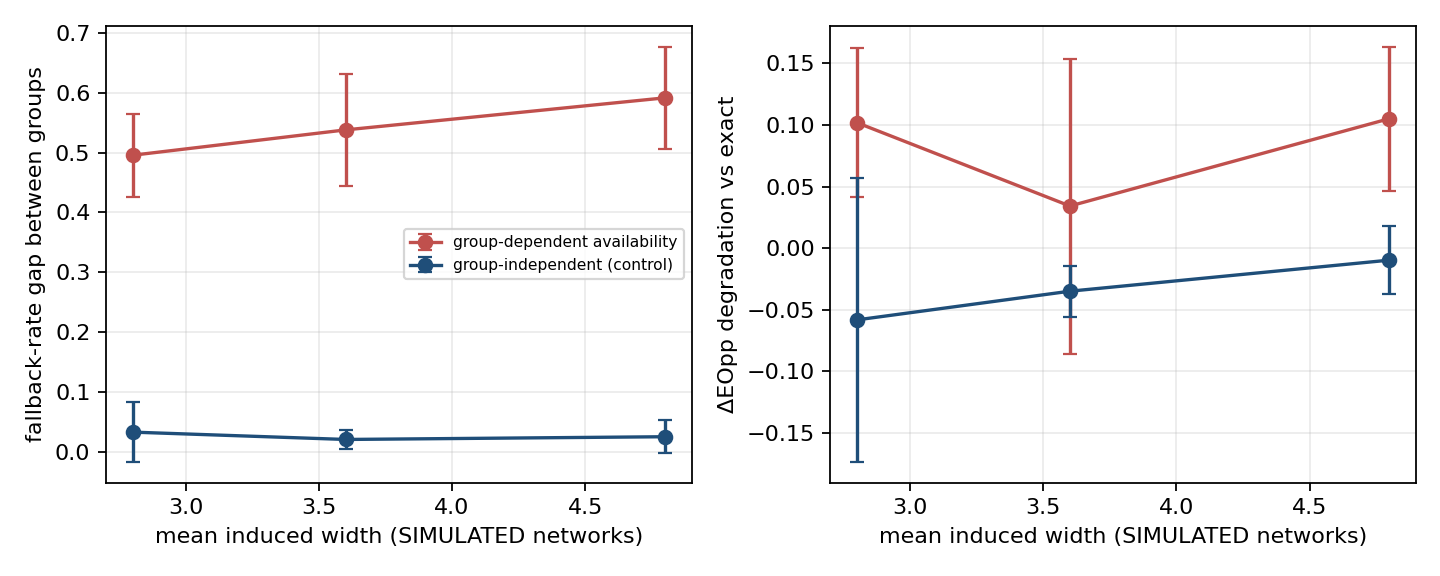


running factorial grid (treewidth × availability gap × 5 seeds, SIMULATED) — a few minutes ...

Factorial grid (SIMULATED): availability of group 1 (group 0 fixed at 0.9; 0.9 = no group dependence = control)

fallback_gap


avail_g1,0.3,0.5,0.7,0.9
max_parents,,,,
2,0.603,0.496,0.319,0.023
3,0.656,0.538,0.344,0.016
4,0.773,0.592,0.373,0.021



flip_gap


avail_g1,0.3,0.5,0.7,0.9
max_parents,,,,
2,0.075,0.071,0.058,0.062
3,0.064,0.061,0.046,0.030
4,0.086,0.069,0.047,0.008



dEOpp_degradation


avail_g1,0.3,0.5,0.7,0.9
max_parents,,,,
2,0.107,0.102,0.043,-0.078
3,0.033,0.034,0.019,-0.036
4,0.118,0.105,0.038,-0.006


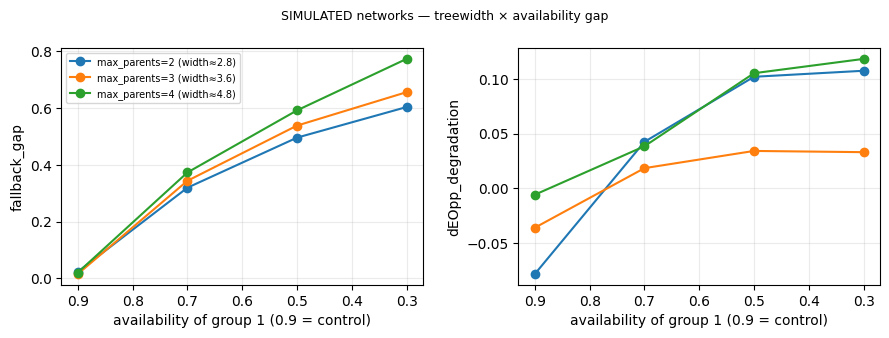

In [22]:
S5 = MET("exp5_aggregate"); p5 = S5[S5.fallback == "prior"]
print("Main synthetic study (SIMULATED): dependent availability vs no-dependence control, by induced width")
show(p5[["max_parents", "induced_width_mean", "n_seeds", "fallback_gap_dep_mean", "fallback_gap_ind_mean", "fallback_gap_diff_mean", "fallback_gap_diff_lo", "fallback_gap_diff_hi",
         "flip_gap_diff_mean", "dEOpp_degradation_dep_mean", "dEOpp_degradation_ind_mean", "dEOpp_degradation_diff_mean", "dEOpp_degradation_diff_lo", "dEOpp_degradation_diff_hi"]])
fig("fig_synthetic_mechanism.png")

from src.synth import run_mechanism
S = C["synthetic"]; f5 = pathlib.Path(OUT) / "metrics" / "exp5b_factorial.csv"
if not f5.exists():
    print("\nrunning factorial grid (treewidth × availability gap × 5 seeds, SIMULATED) — a few minutes ...")
    rows = []
    for w in S["widths"]:
        for a1 in (0.9, 0.7, 0.5, 0.3):                          # group-1 availability; 0.9 = no group dependence (control)
            for seed in C["seeds"]:
                rows += [dict(avail_g0=0.9, avail_g1=a1, **r) for r in run_mechanism(w, a1 < 0.9, seed, (0.9, a1), n_val=1500, n_test=3000,
                                                                                    budget_q=PQ, capacity=C["capacity"], n_vars=S["n_vars"]) if r["fallback"] == "prior"]
    pd.DataFrame(rows).to_csv(f5, index=False)
F5 = pd.read_csv(f5)
gt = F5.groupby(["max_parents", "avail_g1"]).agg(induced_width=("induced_width", "mean"), n_seeds=("seed", "nunique"), fallback_gap=("fallback_gap", "mean"),
                                                   flip_gap=("flip_gap", "mean"), dEOpp_degradation=("dEOpp_degradation", "mean"))
print("\nFactorial grid (SIMULATED): availability of group 1 (group 0 fixed at 0.9; 0.9 = no group dependence = control)")
for k in ("fallback_gap", "flip_gap", "dEOpp_degradation"):
    print("\n" + k); show(gt[k].unstack("avail_g1"))
fa, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, k in zip(axs, ("fallback_gap", "dEOpp_degradation")):
    for w, d in gt.reset_index().groupby("max_parents"):
        ax.plot(d.avail_g1, d[k], marker="o", label=f"max_parents={w} (width≈{d.induced_width.mean():.1f})")
    ax.set_xlabel("availability of group 1 (0.9 = control)"); ax.set_ylabel(k); ax.grid(alpha=.25); ax.invert_xaxis()
axs[0].legend(fontsize=7); fa.suptitle("SIMULATED networks — treewidth × availability gap", fontsize=9); plt.tight_layout(); plt.show()

## 14 · Wall-clock latency — measured **separately** from the deterministic op budgets
Repeated timed batches (`time.perf_counter`); hardware dependent and never used to define a budget.

In [23]:
LAT = MET("latency"); show(LAT[["method", "ms_per_query_median", "ms_q1", "ms_q3", "batches", "queries_per_batch", "python", "machine"]], 3)

,method,ms_per_query_median,ms_q1,ms_q3,batches,queries_per_batch,python,machine
0,ve_min_fill,0.225,0.223,0.226,5,300,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39
1,ve_min_weight,0.229,0.227,0.233,5,300,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39
2,ve_min_degree,0.229,0.226,0.229,5,300,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39
3,clique_tree_min_fill,1.093,1.066,1.107,5,300,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39
4,clique_tree_min_weight,1.708,1.697,1.716,5,300,3.13.18,Linux-6.6.159+-x86_64-with-glibc2.39


## 15 · Post-hoc diagnostics: why validation-chosen fallbacks can fail on the test period
> **EXPLORATORY / POST-HOC.** Nothing below is used to select, tune or change any method. The "oracle" column peeks at test outcomes and is a *diagnostic only* — it is not a method and must never be reported as one.

The release is date-ordered and split positionally, so the **base rate drifts** between train, validation and test. A fallback chosen on validation can therefore rank differently on test.

In [24]:
print("Base rate by chronological split, and realised outreach rate at the validation-fixed threshold (exact inference, test):")
zn = np.load(f"{OUT}/runs/artifacts_natural.npz", allow_pickle=True)
show(pd.DataFrame({"positive_rate": {k: v.y.mean() for k, v in splits.items()},
                   "target_capacity": {k: C["capacity"] for k in splits},
                   "realised_selection_rate_exact": {"train": np.nan, "val": C["capacity"], "test": float(zn["d_exact"].mean())}}))
print("Thresholds are fixed on validation, so the realised test selection rate differs from the nominal capacity whenever the base rate / score distribution shifts.")

cands = {"global_prior": "prior", "cand_blanket_small": "blanket_small", "cand_blanket_medium": "blanket_medium", "cand_age_prior": "age_prior"}
rows = []
for w in ("natural", "dependent"):
    for meth, fbn in cands.items():
        t = R[(R.tag == "main") & np.isclose(R.q, PQ) & (R.workload == w) & (R.method == meth)]
        c = CH[(CH.tag == "main") & np.isclose(CH.q, PQ) & (CH.workload == w)]
        rows.append(dict(workload=w, candidate=fbn, uses_protected=bool(C["fallbacks"][fbn].get("uses_protected", False)),
                         VAL_ap_loss=c[f"val_{fbn}_ap_loss"].mean(), VAL_worst_flip=c[f"val_{fbn}_worst_flip"].mean(),
                         TEST_ap_loss=(R[(R.tag == "main") & np.isclose(R.q, PQ) & (R.workload == w) & (R.method == "exact")].ap.mean() - t.ap.mean()),
                         TEST_worst_flip=t.worst_group_flip.mean(), TEST_dEOpp_supported=t.dEOpp_supported.mean()))
V = pd.DataFrame(rows)
print("\nValidation statistics the rule used  vs  what each candidate actually did on test (mean over seeds):"); show(V.set_index(["workload", "candidate"]))
for w in ("natural", "dependent"):
    v = V[V.workload == w]; ok = v[v.VAL_ap_loss <= TOL]
    pick_val = ok.sort_values(["VAL_worst_flip", "VAL_ap_loss"]).candidate.iloc[0] if len(ok) else "(none feasible)"
    best = v.TEST_worst_flip.min(); oracle = v[v.TEST_worst_flip <= best + 0.01].candidate.tolist()      # ties within 0.01 count as equal
    print(f"{w}: validation picks '{pick_val}'; ORACLE (test worst-flip, ties within 0.01) = {oracle}  "
          + ("-> consistent: the validation choice transferred to the test period" if pick_val in oracle
             else "-> MISMATCH: the validation estimate did not transfer to the test period (distribution shift / small groups)"))

Base rate by chronological split, and realised outreach rate at the validation-fixed threshold (exact inference, test):


,positive_rate,target_capacity,realised_selection_rate_exact
train,0.048,0.2,NaN
val,0.111,0.2,0.200
test,0.308,0.2,0.383


Thresholds are fixed on validation, so the realised test selection rate differs from the nominal capacity whenever the base rate / score distribution shifts.

Validation statistics the rule used  vs  what each candidate actually did on test (mean over seeds):


uses_protected  VAL_ap_loss  VAL_worst_flip  TEST_ap_loss  TEST_worst_flip  TEST_dEOpp_supported
workload  candidate                                                                                                       
natural   prior                    False        0.004           0.078         0.071            0.303                 0.303
          blanket_small            False        0.000           0.039         0.011            0.038                 0.418
          blanket_medium           False       -0.001           0.039        -0.000            0.038                 0.423
          age_prior                 True        0.003           0.054         0.067            0.198                 0.717
dependent prior                    False        0.005           0.299         0.093            0.473                 0.305
          blanket_small            False        0.002           0.211        -0.003            0.134                 0.336
          blanket_medium           False        0.003           0.211        -0.012            0.134                 0.340
          age_prior                 True       -0.010           0.225         0.078            0.402                 0.905

natural: validation picks 'blanket_medium'; ORACLE (test worst-flip, ties within 0.01) = ['blanket_small', 'blanket_medium']  -> consistent: the validation choice transferred to the test period
dependent: validation picks 'blanket_small'; ORACLE (test worst-flip, ties within 0.01) = ['blanket_small', 'blanket_medium']  -> consistent: the validation choice transferred to the test period


## 16 · Findings (generated from the numbers above), checklist and ethics
Sentences are produced from the computed results so they stay correct whatever the real data say. A negative or null result is reported as such.

In [25]:
def verdict(r):
    if r.hi < 0: return "proposed has LOWER ΔEOpp (CI excludes 0)"
    if r.lo > 0: return "proposed has HIGHER ΔEOpp, i.e. is WORSE (CI excludes 0)"
    return "no detectable difference (CI includes 0)"
Bc = B[(B.kind == "proposed_minus_comparator")]
print("MECHANISM")
wc = WC[np.isclose(WC.q, PQ) & (WC.method == "global_prior")].iloc[0]
nat_gap = A.loc[("natural", "global_prior"), "fallback_gap"]
print(f" • Natural evidence only (REAL): at {BUD[PQ]} ops the global-fallback rate gap between supported groups is {nat_gap:.3f} "
      f"(overall fallback rate {A.loc[('natural','global_prior'),'fallback_rate']:.3f}).")
print(f" • SYNTHETIC group-dependent masking vs matched control (global fallback, mean over seeds): fallback-rate-gap difference "
      f"{wc.fallback_gap_diff_mean:+.3f} [{wc.fallback_gap_diff_lo:+.3f}, {wc.fallback_gap_diff_hi:+.3f}].")
ctl = p5.fallback_gap_ind_mean.mean(); dep = p5.fallback_gap_dep_mean.mean()
print(f" • SIMULATED networks: mean fallback-rate gap {dep:.3f} with group-dependent availability vs {ctl:.3f} in the no-dependence control "
      f"-> the disparity is {'produced by the evidence-dependent workload' if dep > ctl + 0.05 else 'NOT clearly produced by the workload in this simulation'}.")
print("\nMITIGATION (primary question: can a budget-aware fallback reduce the fairness degradation at a fixed budget?)")
for _, r in Bc[Bc.confirmatory].iterrows():
    print(f" • CONFIRMATORY, natural, {r.comparison}: {r.estimate:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}], Holm p={r.p_holm:.3f} -> {verdict(r)}")
for _, r in Bc[(Bc.workload == "dependent")].iterrows():
    print(f" • exploratory, dependent (SYNTHETIC), {r.comparison}: {r.estimate:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}] -> {verdict(r)}")
pk = CH[(CH.tag == "main") & (CH.workload == "dependent") & np.isclose(CH.q, PQ)].proposed.value_counts().to_dict()
print(f" • fallbacks chosen by the proposed rule (dependent, primary budget): {pk}; group-unaware variant: "
      f"{CH[(CH.tag == 'main') & (CH.workload == 'dependent') & np.isclose(CH.q, PQ)].proposed_unaware.value_counts().to_dict()}")
conf_ok = (Bc[Bc.confirmatory].hi < 0).all() and (Bc[Bc.confirmatory].p_holm < 0.05).all()
print("\nOVERALL:", "the proposed rule reduces ΔEOpp in all confirmatory comparisons." if conf_ok else
      "the mitigation claim is NOT confirmed in the pre-declared confirmatory family — report this as a (correctly qualified) negative/null finding, with the §15 diagnostics as the explanation to investigate.")
print("\nLIMITS: positional split with strong base-rate drift; no customer IDs (repeated-customer dependence uncontrolled); contacted-sample selection "
      "(historical subscriptions among contacted customers do not describe never-contacted people); synthetic masks are simulated; no causal marketing claims.")

MECHANISM
 • Natural evidence only (REAL): at 11 ops the global-fallback rate gap between supported groups is 0.222 (overall fallback rate 0.201).
 • SYNTHETIC group-dependent masking vs matched control (global fallback, mean over seeds): fallback-rate-gap difference +0.292 [+0.203, +0.381].
 • SIMULATED networks: mean fallback-rate gap 0.542 with group-dependent availability vs 0.026 in the no-dependence control -> the disparity is produced by the evidence-dependent workload.

MITIGATION (primary question: can a budget-aware fallback reduce the fairness degradation at a fixed budget?)
 • CONFIRMATORY, natural, proposed - global_prior: +0.120 [+0.015, +0.226], Holm p=0.036 -> proposed has HIGHER ΔEOpp, i.e. is WORSE (CI excludes 0)
 • CONFIRMATORY, natural, proposed - util_sel: -0.294 [-0.370, -0.210], Holm p=0.006 -> proposed has LOWER ΔEOpp (CI excludes 0)
 • CONFIRMATORY, natural, proposed - thr_adj_post_budget: +0.106 [-0.006, +0.251], Holm p=0.080 -> no detectable difference (CI i

In [26]:
checks = []
def chk(name, ok): checks.append(dict(requirement=name, status="PASS" if bool(ok) else "FAIL"))
EJ = json.load(open(f"{OUT}/metrics/exp1_exact_agreement.json")); CJ = json.load(open(f"{OUT}/metrics/cgm.json"))
chk("Pre-contact only: no 'duration'/post-contact column in any split", not any("duration" in c.lower() for f in splits.values() for c in f.columns))
chk("Provenance recorded (SHA-256, rows, access date)", pathlib.Path(f"{OUT}/logs/data_provenance.json").exists())
chk("Dataset matches published UCI counts (41,188 x 21; 4,640 yes)", prov["matches_published_uci_counts"])
chk("Exp 1: VE (3 heuristics) = clique tree = enumeration <= 1e-6 (fitted BN, real + masked evidence)", all(v["passed"] for v in EJ.values()))
chk("Exp 1: random-network C-GM passes", CJ["passed"])
chk("VE with >=2 elimination heuristics + clique tree + sum-product calibration", {"ve_min_fill", "ve_min_weight", "clique_tree_min_fill"} <= set(X2.method))
chk("Factor-entry ops and peak factor size measured", {"ops_mean", "peak_factor_max"} <= set(X2.columns))
chk("Exp 2: cost/peak/memory across natural + synthetic workloads", X2.workload.nunique() >= 4 and "mem_peak_kb" in X2)
chk("Deterministic operation budgets (op counts, not wall-clock)", len(BUD) == len(C["budget_quantiles"]))
chk("Exp 3: fallback rate + flips by group + approximation error", {"fallback_rate", "flip"} <= set(GT.columns) and "tv_max" in R)
chk("Exp 4: proposed vs global/util/threshold-adjusted/fair-exact at matched utility", {"proposed", "global_prior", "util_sel", "thr_adj_post_budget", "fair_exact"} <= set(R.method))
chk("Group-unaware routing comparison (proposed_unaware never uses protected attr)", "proposed_unaware" in set(R.method) and not R[R.method == "proposed_unaware"].group_label_at_decision.any())
chk("Predictive baselines: logistic regression + gradient-boosted trees", {"logreg", "gbt"} <= set(PB.method))
chk("Exp 5: synthetic networks incl. no-group-dependence control", S5.shape[0] > 0 and f5.exists())
chk("Ablations A1-A4 present", {"util_sel", "global_prior"} <= set(R.method) and "ablation_no_simplification" in set(R.tag) and (np.isclose(R.q, 1.0)).any())
chk("Robustness: heuristics, densities, discretisation, budgets, masks, thresholds", {"robust_heuristic_min_weight", "robust_structure_sparse", "robust_structure_dense", "robust_discretization", "robust_capacity_0.1"} <= set(R.tag) and R.workload.nunique() == 3)
chk(">= 5 seeds for every stochastic part", len(C["seeds"]) >= 5 and R[R.workload == "dependent"].groupby("tag").seed.nunique().min() >= 5)
chk(">= 1,000 bootstrap replicates, block resampling", B.n_boot.min() >= 1000)
chk("Holm correction on the declared confirmatory family", B.loc[B.confirmatory, "p_holm"].notna().all())
chk("Small groups: denominators reported, <30 flagged exploratory", {"exploratory_tpr", "exploratory_fpr"} <= set(gd.columns))
chk("AUROC, AP, balanced accuracy, decision agreement, log loss, Brier, max & groupwise marginal error, TV", {"auroc", "ap", "balanced_acc", "agree_exact", "log_loss", "brier", "tv_max", "tv_mean"} <= set(R.columns))
chk("Wall-clock latency measured separately in repeated batches", (LAT.batches >= 3).all())
chk("Elimination traces, induced cliques, max clique size, evidence propagation shown (§4)", True)
chk("Synthetic masks / networks labelled SYNTHETIC / SIMULATED", True)
CK = pd.DataFrame(checks); display(CK)
print("ALL CHECKS PASS" if (CK.status == "PASS").all() else "Some checks FAILED - investigate before submitting (a FAIL on the published-counts check means the file is not the genuine UCI release)")
json.dump(dict(provenance=prov, checks=CK.to_dict("records"), budgets=BUD, seeds=C["seeds"]), open(f"{OUT}/summary.json", "w"), indent=1, default=str)

,requirement,status
0,Pre-contact only: no 'duration'/post-contact column in any split,PASS
1,"Provenance recorded (SHA-256, rows, access date)",PASS
2,"Dataset matches published UCI counts (41,188 x 21; 4,640 yes)",PASS
3,"Exp 1: VE (3 heuristics) = clique tree = enumeration <= 1e-6 (fitted BN, rea...",PASS
4,Exp 1: random-network C-GM passes,PASS
5,VE with >=2 elimination heuristics + clique tree + sum-product calibration,PASS
6,Factor-entry ops and peak factor size measured,PASS
7,Exp 2: cost/peak/memory across natural + synthetic workloads,PASS
8,"Deterministic operation budgets (op counts, not wall-clock)",PASS
9,Exp 3: fallback rate + flips by group + approximation error,PASS


ALL CHECKS PASS


### Ethical questions (drafts for the report — complete in your own words)
* **Should missing evidence lead to slower or less reliable decisions?** Not by default: the budget trip rate by group (§7) shows who pays. Customers with more `unknown` fields (older/younger groups, see §1) are exactly those pushed to coarser fallbacks, so reliability should be audited by group and a group-unaware fallback preferred (§8).
* **Who bears the cost of fallback errors?** Customers wrongly *not* selected lose an offer (lost TPR); customers wrongly selected are contacted unnecessarily. §7 reports both via decision flips and TPR by group; small groups are exploratory, not "fair by lack of evidence".
* **Can historical subscription among contacted customers justify conclusions about people never contacted?** No — the data are conditional on having been contacted (selection into the sample). All results are about this audited pipeline, not about causal marketing effects or the general population.

### Before you submit
Replace every `fillin` placeholder (names, roll numbers, commit, interpretation), recompile `report/` and `slides/` from `results/` (never hand-type numbers), complete `docs/contributions.md`, extend `docs/related_work.md`, and disclose AI assistance per course policy. Both students must be able to explain every cell above.

In [28]:
import zipfile
import os

# Create a ZIP file of the entire results/ directory
output_zip_path = '/content/all_outputs.zip'
with zipfile.ZipFile(output_zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root_dir, dirs, files in os.walk('results'):
        for file in files:
            file_path = os.path.join(root_dir, file)
            arcname = os.path.relpath(file_path, 'results')
            zipf.write(file_path, arcname)

print(f'All experiment outputs successfully compressed into: {output_zip_path}')

All experiment outputs successfully compressed into: /content/all_outputs.zip


In [29]:
from google.colab import files
try:
    files.download('/content/all_outputs.zip')
except Exception as e:
    print(f'Could not trigger automatic browser download: {e}')
    print('You can manually download "all_outputs.zip" from the Colab file explorer on the left.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>